# 마케팅 캠페인 A/B 테스트 분석

| 항목 | 내용 |
| --- | --- |
| 데이터 | [Marketing A/B Testing (Kaggle, faviovaz)](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) |
| 파일 | `marketing_AB.csv` (이 노트북과 같은 폴더에 두고 실행) |
| 내려받은 날짜 | 2026-11-06 *(직접 내려받은 날짜로 수정)* |
| 실험 내용 | 사용자 대부분에게는 **광고(ad)** 를, 일부에게는 대조군으로 **공익광고(psa)** 를 보여 주고 구매 전환 여부를 기록 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 42                       # 난수를 쓰는 셀이 생기면 이 값으로 고정
np.random.seed(SEED)

pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

# 1. 데이터 점검

검정 결과가 아무리 그럴듯해도 데이터가 오염되어 있으면 의미가 없습니다. 그래서 **검정보다 먼저** 아래 네 가지를 확인합니다.

1. 기본 확인: 행 수, 컬럼, 자료형, 결측치
2. 중복 확인: 같은 사용자 ID가 두 번 이상 나오는가?
3. 배정 일관성: 처치 라벨이 어긋난 행은 없는가?
4. SRM 점검: 배정 비율이 의도대로인가?

### 1-1. 기본 확인: 행 수, 컬럼, 자료형, 결측치

결론적으로 p값을 계산하기 전에 "이 데이터가 실험 설게대로 생겼는가"를 먼저 확인

현재 이 데이터는 사용자 588,101명에게 광고(ad) 또는 공익광고(psa)를 보여주고, 구매(전환)했는지를 기록한 실험이다.

### ①	데이터 읽기와 기본 정보 확인

In [2]:
raw = pd.read_csv("marketing_AB.csv")
N_RAW = len(raw)

print(f"행 수: {N_RAW:,} / 컬럼 수: {raw.shape[1]}")
print()
print(raw.dtypes)
print()
print("컬럼별 결측치:")
print(raw.isna().sum())
raw.head()

행 수: 588,101 / 컬럼 수: 7

Unnamed: 0       int64
user id          int64
test group         str
converted         bool
total ads        int64
most ads day       str
most ads hour    int64
dtype: object

컬럼별 결측치:
Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


**컬럼 설명**

| 컬럼 | 의미 | 자료형 |
| --- | --- | --- |
| `Unnamed: 0` | CSV 저장 시 함께 저장된 행 번호로 보임 (아래에서 확인) | 정수 |
| `user id` | 사용자 ID | 정수 |
| `test group` | 배정 그룹: `ad`(광고, 실험군) / `psa`(공익광고, 대조군) | 문자열 |
| `converted` | 구매 전환 여부 → **주 지표(비율)** | bool |
| `total ads` | 실험 기간에 본 광고 수 | 정수 |
| `most ads day` | 광고를 가장 많이 본 요일 | 문자열 |
| `most ads hour` | 광고를 가장 많이 본 시간대(0~23시) | 정수 |

`Unnamed: 0`이 정말 행 번호일 뿐인지 확인합니다.


데이터 크기 : 588,101행, 7개 컬럼

자료형 : 각 컬럼이 내용에 맞는 형태로 읽힘. 숫자 컬럼(user id, total ads, most ads hour)은 정수(int64), 글자 컬럼(test group, most ads day)은 문자열(str), 전환 여부(converted)는 참/거짓(bool)이다. 숫자여야 할 컬럼이 문자열로 읽혔다면 중간에 글자가 섞였다는 신호인데, 그런 문제는 없음.

결측치 : 모든 컬럼이 0개, 빈칸 없음.

확인히 필요한 컬럼 : 7개중 Unnamed: 0만 이름이 없는 컬럼입니다. 무엇을 담고 있는지 이름만으로는 알 수 없으므로 다음 셀에서 내용을 확인예정

### ② Unnamed: 0 컬럼 내용 확인

In [3]:
# Unnamed: 0 컬럼의 값이 행 번호(0, 1, 2, ...)와 같은지 확인
row_number = np.arange(N_RAW)                     # 행 번호: 0, 1, 2, ..., 588100
same = raw["Unnamed: 0"].values == row_number     # 줄마다 비교: 같으면 True, 다르면 False

compare = pd.DataFrame({
    "행 번호": row_number,
    "Unnamed: 0 값": raw["Unnamed: 0"].values,
    "같은가?": same,
})

print("▶ 맨 앞 3줄")
print(compare.head(3).to_string(index=False))
print()
print("▶ 맨 뒤 3줄")
print(compare.tail(3).to_string(index=False))
print()
print(f"같은 줄 수: {same.sum():,}개 / 전체 {N_RAW:,}개")
print("588,101개 전부 행 번호와 같은가?", same.all())

▶ 맨 앞 3줄
 행 번호  Unnamed: 0 값  같은가?
    0             0  True
    1             1  True
    2             2  True

▶ 맨 뒤 3줄
  행 번호  Unnamed: 0 값  같은가?
588098        588098  True
588099        588099  True
588100        588100  True

같은 줄 수: 588,101개 / 전체 588,101개
588,101개 전부 행 번호와 같은가? True


Unnamed: 0의 값 588,101개가 전부 행 번호(0, 1, 2, …, 588100)와 같습니다(True). 파일을 저장할 때 행 번호가 함께 저장되어 생긴 불필요한 컬럼입니다. 사용자에 대한 정보가 없으므로 삭제합니다

### ③	불필요한 컬럼 삭제와 컬럼 이름 정리

In [4]:
df = (raw.drop(columns="Unnamed: 0")
         .rename(columns={"user id": "user_id", "test group": "group",
                          "total ads": "total_ads", "most ads day": "most_ads_day",
                          "most ads hour": "most_ads_hour"}))
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   user_id        588101 non-null  int64
 1   group          588101 non-null  str  
 2   converted      588101 non-null  bool 
 3   total_ads      588101 non-null  int64
 4   most_ads_day   588101 non-null  str  
 5   most_ads_hour  588101 non-null  int64
dtypes: bool(1), int64(3), str(2)
memory usage: 28.1 MB


**값의 범위 점검:** 결측치가 없어도 "있을 수 없는 값"이 들어 있을 수 있습니다. 범주형 컬럼은 허용된 값만 있는지, 숫자형 컬럼은 가능한 범위 안에 있는지 확인합니다.

##### Unnamed: 0 컬럼을 삭제해 컬럼이 7개에서 6개로 줄었고, 행은 588,101개 그대로다. 공백이 있던 컬럼 이름 다섯 개를 밑줄로 바꿨고, 모든 컬럼에 결측치가 없음을 다시 확인했다.

### ④	값의 범위 점검

In [5]:
# [1-1-④] 값의 범위 점검
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

checks = {
    "group 값이 ad/psa뿐인가":         df["group"].isin(["ad", "psa"]).all(),
    "converted가 True/False뿐인가":    df["converted"].isin([True, False]).all(),
    "most_ads_day가 7개 요일뿐인가":   df["most_ads_day"].isin(DAYS).all(),
    "most_ads_hour가 0~23 사이인가":   df["most_ads_hour"].between(0, 23).all(),
    "total_ads가 1 이상인가":          (df["total_ads"] >= 1).all(),
}
for k, v in checks.items():
    print(f"{'✅' if v else '❌'} {k}")

print()
n_ad, n_psa = (df["group"] == "ad").sum(), (df["group"] == "psa").sum()
print(f"group 분포: ad {n_ad:,}명 ({n_ad / len(df):.1%}) / psa {n_psa:,}명 ({n_psa / len(df):.1%})")
print(f"광고 그룹은 공익광고 그룹의 {n_ad / n_psa:.1f}배")

n_conv = df["converted"].sum()
print(f"converted 분포: 구매 {n_conv:,}명 / 미구매 {len(df) - n_conv:,}명")
print(f"전체 전환율: {n_conv / len(df):.2%}")

✅ group 값이 ad/psa뿐인가
✅ converted가 True/False뿐인가
✅ most_ads_day가 7개 요일뿐인가
✅ most_ads_hour가 0~23 사이인가
✅ total_ads가 1 이상인가

group 분포: ad 564,577명 (96.0%) / psa 23,524명 (4.0%)
광고 그룹은 공익광고 그룹의 24.0배
converted 분포: 구매 14,843명 / 미구매 573,258명
전체 전환율: 2.52%


`total_ads`는 중앙값이 13개인데 최댓값은 2,000개가 넘습니다. 오른쪽 꼬리가 매우 긴 분포입니다. 하지만 **이 값은 지우지 않고 유지합니다.** 광고를 많이 본 헤비 유저일 수 있는 실제 값이고, 주 지표(`converted`)도 아니기 때문입니다.

결과에 따른 해석

- 값의 범위 (✅ 다섯 줄)

다섯 가지 점검을 모두 통과했습니다. 그룹 라벨에 오타가 없고, 요일은 7개뿐이며, 시간은 0~23시 안에 있고, 모든 사용자가 광고를 1개 이상 봤습니다. 마지막 점검은 특히 중요합니다. 광고를 0개 본 사람은 "처치를 받지 않은 사람"인데, 그런 사람이 실험에 섞여 있지 않다는 뜻입니다. 결측치 0개(1-1-①)와 합치면 모든 칸이 채워져 있고 모두 올바른 범위 안에 있습니다.

- 그룹 크기 (group 분포, 24.0배)

광고 그룹 96.0%, 공익광고 그룹 4.0%로, 광고 그룹이 약 24배 큽니다. 이것이 정상인지는 1-4 SRM 점검에서 판단하고, 여기서는 숫자만 기록합니다. 다만 한 가지는 미리 알아 둡니다. 두 그룹 비교의 정밀도는 작은 그룹(2만 3천 명)에 묶이기 때문에, 나중에 신뢰구간과 MDE를 해석할 때 이 숫자가 중요해집니다.

- 전환 (converted 분포, 전체 전환율)

588,101명 중 14,843명이 구매해 전환율은 2.52%입니다. 100명 중 2~3명꼴인 드문 사건이라, 그룹 간 차이도 작게 나올 가능성이 큽니다. 그룹별 전환율은 아직 보지 않습니다. 2단계에서 가설을 먼저 정한 뒤에 봐야 하기 때문입니다.

한 줄 결론 : 있을 수 없는 값은 없다. 그룹은 96 : 4로 나뉘어 있고(정상 여부는 1-4에서 판단), 전체 전환율은 2.52%다.

💡 psa란? Public Service Announcement(공익광고)의 약자입니다. "광고를 아예 안 보여 준" 것이 아니라 "다른 광고(공익광고)를 보여 준" 대조군입니다. 그래서 이 실험이 답하는 질문은 "광고가 효과 있나?"보다 "우리 광고가 공익광고보다 구매를 더 이끌어 내나?"에 가깝습니다.

### ⑤	total_ads 분포 그래프

▶ 요약 통계
count   588101.0000
mean        24.8209
std         43.7152
min          1.0000
25%          4.0000
50%         13.0000
75%         27.0000
max       2065.0000
Name: total_ads, dtype: float64

▶ 상위 구간 백분위수 (이 값 이하로 본 사용자 비율)
  90.0%: 57개 이하
  95.0%: 88개 이하
  99.0%: 202개 이하
  99.9%: 500개 이하

▶ 가장 흔한 값(최빈값): 1개 → 56,606명
▶ 500개 초과: 585명 / 1,000개 초과: 36명

▶ IQR 규칙: IQR = 27 - 4 = 23, 기준선 = 27 + 1.5 × 23 = 61.5
  기준선을 넘는 사용자: 52,057명 (8.9%)


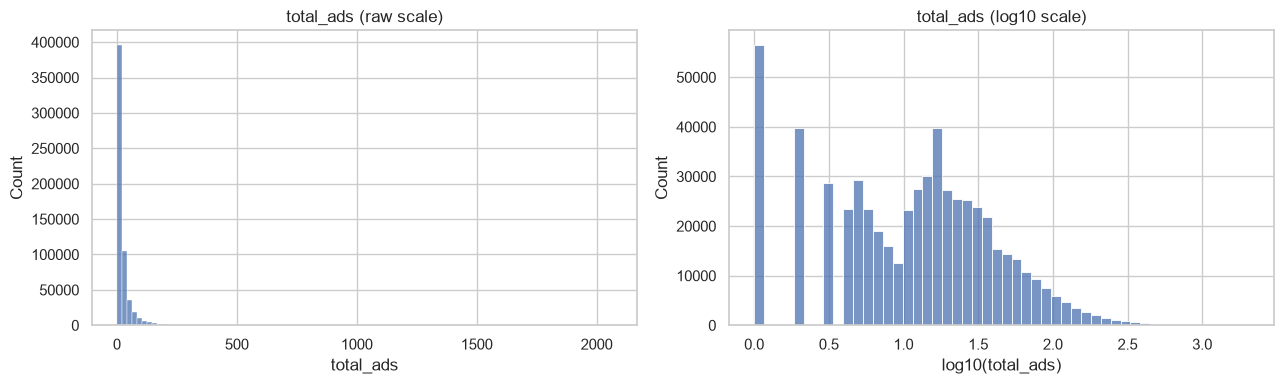

In [6]:
# [1-1-⑤] total_ads 분포 확인: 요약 통계와 그래프
t = df["total_ads"]

# (1) 요약 통계
print("▶ 요약 통계")
print(t.describe())

# (2) 상위 구간 백분위수
print("\n▶ 상위 구간 백분위수 (이 값 이하로 본 사용자 비율)")
for q in [0.90, 0.95, 0.99, 0.999]:
    print(f"  {q:.1%}: {t.quantile(q):,.0f}개 이하")

# (3) 가장 흔한 값과 극단값 개수
print(f"\n▶ 가장 흔한 값(최빈값): {t.mode()[0]}개 → {(t == t.mode()[0]).sum():,}명")
print(f"▶ 500개 초과: {(t > 500).sum():,}명 / 1,000개 초과: {(t > 1000).sum():,}명")

# (4) IQR 규칙을 적용하면 몇 명이 '이상치'로 잡히나
q1, q3 = t.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
n_out = (t > upper).sum()
print(f"\n▶ IQR 규칙: IQR = {q3:.0f} - {q1:.0f} = {iqr:.0f}, 기준선 = {q3:.0f} + 1.5 × {iqr:.0f} = {upper}")
print(f"  기준선을 넘는 사용자: {n_out:,}명 ({n_out / len(t):.1%})")

# (5) 그래프: 왼쪽 원래 값, 오른쪽 로그 척도
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(t, bins=100, ax=axes[0])
axes[0].set_title("total_ads (raw scale)")
sns.histplot(np.log10(t), bins=50, ax=axes[1])
axes[1].set_title("total_ads (log10 scale)")
axes[1].set_xlabel("log10(total_ads)")
plt.tight_layout()
plt.show()

결과에 따른 해석

- 요약 통계 → 오른쪽 꼬리가 긴 분포

| 비교 | 값 | 알 수 있는 것 |
| --- | --- | --- |
| 평균 vs 중앙값 | 24.8 vs 13 | 평균이 약 2배 → 소수의 큰 값이 평균을 끌어올림 |
| 표준편차 vs 평균 | 43.7 vs 24.8 | 표준편차가 더 큼 → 대칭 분포가 아님 |
| 사분위수 (Q1 / 중앙값 / Q3) | 4 / 13 / 27 | 가운데 50%는 4~27개를 봄 (평범한 사용자) |
| 최댓값 vs 중앙값 | 2,065 vs 13 | 최댓값이 중앙값의 약 159배 → 꼬리가 매우 김 |

그래서 이 변수는 "평균 ± 표준편차"보다 중앙값과 사분위수로 설명하는 것이 정확합니다.

- 상위 구간 → 극단값은 극소수

99%의 사용자가 202개 이하를 봤고, 1,000개 넘게 본 사람은 36명뿐입니다. 가장 흔한 값은 1개(56,606명)입니다. 대부분은 광고를 적게 보고, 아주 일부가 매우 많이 봅니다.

- 그래프 → 하나로 이어진 분포

왼쪽 그래프는 막대가 왼쪽 끝에 몰려 있고 낮은 꼬리가 2,000 근처까지 이어집니다. 오른쪽 로그 척도 그래프에서는 분포가 끊김 없이 하나로 이어져 있습니다. 입력 오류라면 보통 엉뚱한 곳에 따로 떨어진 덩어리가 보이는데, 그런 모습이 없습니다.

- IQR 규칙 → 기계적으로 지우면 안 되는 이유

IQR 규칙의 기준선은 61.5개이고, 이를 넘는 사용자는 **52,057명(8.9%)**입니다. 이 규칙대로 지우면 11명 중 1명꼴로 사라집니다. 이상한 값 몇 개가 아니라 광고를 많이 본 사용자층 전체를 빼는 셈입니다.

## 1-2. 중복 확인

- 행 전체가 똑같은 중복 행이 있는가?
- 같은 `user_id`가 두 번 이상 나오는가? (한 사용자는 한 번만 실험에 들어가야 합니다)

### ① 완전 중복행 확인

In [7]:
## [1-2-①] 완전 중복 행 확인: 6개 컬럼 값이 모두 똑같은 행이 있는가
dup_rows = df.duplicated()        # 앞에 나온 행과 모든 값이 같으면 True

print(f"전체 행 수: {len(df):,}개")
print(f"완전 중복 행: {dup_rows.sum():,}개")
print("완전 중복 행이 하나도 없는가?", dup_rows.sum() == 0)

전체 행 수: 588,101개
완전 중복 행: 0개
완전 중복 행이 하나도 없는가? True


결과 해석

- 완전 중복 행 0개 : 588,101개 행 중 6개 컬럼 값이 모두 똑같은 행은 하나도 없습니다. 같은 기록이 두 번 저장된 경우는 없습니다.

- `df`로 검사한 이유 : 원본 `raw`에는 행마다 값이 다른 `Unnamed: 0`(행 번호)이 있어서, 나머지 값이 모두 같은 행이 있어도 "다른 행"으로 판단됩니다. 1-1-③에서 이 컬럼을 먼저 삭제했기 때문에, 이 검사가 **실제 내용을 비교하는 의미 있는 검사**가 되었습니다.

- 남은 확인 : 완전 중복이 없어도, 같은 사용자가 **다른 값으로** 두 번 기록되었을 수 있습니다. 이것은 1-2-②에서 `user_id`만 따로 확인합니다.

### ② 사용자 ID 중복 확인

완전 중복 행 확인 결과를 보면 6개 값이 **모두** 같은 행만 찾았습니다. 하지만 같은 사람이 **다른 값으로** 두 번 기록되었을 수도 있습니다(예: 한 번은 광고 그룹, 한 번은 공익광고 그룹). 그래서 이번에는 `user_id` 컬럼 하나만 보고 같은 사람이 두 번 이상 나오는지 확인합니다.

In [8]:
# ② 사용자 ID 중복 확인: 같은 user_id가 두 번 이상 나오는가

dup_id = df["user_id"].duplicated()      # 앞에 나온 user_id와 같으면 True
n_unique = df["user_id"].nunique()       # 서로 다른 user_id의 개수

print(f"전체 행 수: {len(df):,}개")
print(f"고유 user_id 수: {n_unique:,}명")
print(f"user_id 중복 행: {dup_id.sum():,}개")
print("한 사람 = 한 행인가?", n_unique == len(df))

전체 행 수: 588,101개
고유 user_id 수: 588,101명
user_id 중복 행: 0개
한 사람 = 한 행인가? True


**1-2-② 결과 해석**

- **사용자 ID 중복 0개 :** `user_id` 588,101개가 모두 서로 다릅니다. 한 사람이 두 번 이상 기록된 경우는 없습니다.

- **한 사람 = 한 행 :** 고유 사용자 수(588,101명)와 전체 행 수(588,101개)가 같습니다(`True`). 따라서 행 1개는 사용자 1명이고, **그룹별 행 수를 그대로 사람 수로 쓸 수 있습니다.**

- **완전 중복해 ①과의 관계 :** `user_id`만 비교하는 1-2-②가 더 엄격한 검사입니다. 같은 사람이 다른 값으로 두 번 기록된 경우도 잡아내기 때문입니다. 이 검사를 통과했으므로 1-2-①의 결과(완전 중복 0개)도 자연스럽게 뒷받침됩니다.

---

**📝 1-2 중복 확인 정리**

| 점검 | 결과 | 조치 |
| --- | --- | --- |
| 1-2-① 완전 중복 행 | 0개 | 없음 |
| 1-2-② `user_id` 중복 | 0개 (고유 588,101명 = 전체 588,101행) | 없음 |

**정제 전후: 588,101행 → 588,101행 (제거한 행 없음).** 한 사람은 실험에 한 번만 들어 있습니다.

### 1-3. 배정 일관성

**배정 일관성**이란, 각 사용자가 **하나의 그룹에만, 정확한 라벨로** 기록되어 있는지를 말합니다.

과제 예시처럼 "배정된 그룹(`group`)"과 "실제로 본 페이지(`landing_page`)"가 따로 기록된 데이터라면, 두 라벨이 어긋난 행(control인데 new_page를 본 경우)을 찾아야 합니다.

**이 데이터에는 처치 라벨이 `group` 하나뿐입니다.** 비교할 두 번째 라벨이 없으므로 "두 라벨이 어긋나는" 상황 자체가 생길 수 없습니다. 그래서 이 데이터에 맞게 아래 두 가지로 바꿔서 확인합니다.

| 번호 | 제목 | 확인하는 것 |
| --- | --- | --- |
| 1-3-① | 두 그룹 동시 배정 확인 | 한 사용자가 ad와 psa에 동시에 배정되었는가 |
| 1-3-② | 그룹 라벨 표기 확인 | 원본 라벨에 공백·대소문자 차이 같은 다른 표기가 섞여 있는가 |

#### ① 두 그룹 동시 배정 확인

사용자마다 몇 개의 그룹에 배정되었는지 셉니다. 정상이라면 **모든 사용자가 정확히 1개 그룹**에만 속해야 합니다. 2개로 나오는 사용자가 있다면, 광고와 공익광고를 둘 다 본 사람이라 어느 쪽 효과인지 알 수 없습니다.

In [9]:
# [1-3-①] 두 그룹 동시 배정 확인: 한 사용자가 ad와 psa에 동시에 배정되었는가
groups_per_user = df.groupby("user_id")["group"].nunique()   # 사용자별 배정된 그룹 수

print(f"사용자 수: {len(groups_per_user):,}명")
print("사용자별 배정된 그룹 수 분포:")
print(groups_per_user.value_counts().to_string())
print(f"두 그룹 이상에 배정된 사용자: {(groups_per_user > 1).sum():,}명")

사용자 수: 588,101명
사용자별 배정된 그룹 수 분포:
group
1    588101
두 그룹 이상에 배정된 사용자: 0명


**결과 해석**

- **출력 읽는 법 :** `1    588101`은 "배정된 그룹 수가 1개인 사용자가 588,101명"이라는 뜻입니다. 두 그룹에 동시 배정된 사용자가 있었다면 `2`로 시작하는 줄이 하나 더 나왔을 것입니다.

- **결과 :** 588,101명 전원이 그룹 1개에만 배정되었고, 두 그룹 이상에 배정된 사용자는 **0명**입니다. 광고와 공익광고를 둘 다 본 사람은 없습니다.

- **1-2-②와의 관계:** 1-2-②에서 `user_id`가 모두 다르다는 것을 확인했으므로, 이 결과는 논리적으로 예상된 것입니다. 그래도 "배정이 섞였는가"라는 다른 질문에 대한 직접 확인이므로 남겨 둡니다.

#### ② 그룹 라벨 표기 확인

같은 그룹이라도 `"ad"`, `"ad "`(뒤에 공백), `"AD"`(대문자)처럼 **표기가 다르면 컴퓨터는 서로 다른 그룹으로 셉니다.** 그러면 일부 사용자가 그룹 집계에서 빠지거나 엉뚱한 그룹으로 분류됩니다.

정리하기 전의 **원본 `raw`**에서 라벨을 글자 그대로 확인합니다.

In [10]:
# [1-3-②] 그룹 라벨 표기 확인: 원본 라벨에 공백·대소문자 차이 같은 다른 표기가 섞여 있는가
labels = raw["test group"]          # 정리 전 원본 라벨

print("원본 라벨별 인원 (따옴표 안이 실제 글자 그대로):")
for v, n in labels.value_counts().items():
    print(f"  {v!r}: {n:,}명")

print()
print(f"앞뒤 공백이 있는 라벨: {(labels != labels.str.strip()).sum():,}개")
print(f"대문자가 섞인 라벨: {(labels != labels.str.lower()).sum():,}개")
print(f"원본 고유 라벨 수: {labels.nunique()}개 / 공백·대소문자 정리 후: {labels.str.strip().str.lower().nunique()}개")

원본 라벨별 인원 (따옴표 안이 실제 글자 그대로):
  'ad': 564,577명
  'psa': 23,524명

앞뒤 공백이 있는 라벨: 0개
대문자가 섞인 라벨: 0개
원본 고유 라벨 수: 2개 / 공백·대소문자 정리 후: 2개


**결과 해석**

- **원본 라벨:** 따옴표 안의 글자가 `'ad'`, `'psa'` 두 가지뿐입니다. 인원도 1-1-④와 같습니다(564,577명 / 23,524명).

- **숨은 표기 차이:** 앞뒤 공백 0개, 대문자 0개입니다. 공백과 대소문자를 정리해도 고유 라벨 수가 2개 → 2개로 그대로이므로, **서로 다른 표기로 나뉜 라벨이 없습니다.**

---

**📝 1-3 배정 일관성 정리**

| 점검 | 결과 | 조치 |
| --- | --- | --- |
| 처치 라벨 컬럼 | `group` 하나뿐 → 두 라벨이 어긋나는 상황 자체가 없음 | 이 데이터에 맞게 아래 두 가지로 확인 |
| 1-3-① 두 그룹 동시 배정 | 0명 (588,101명 전원 1개 그룹) | 없음 |
| 1-3-② 라벨 표기 | `'ad'`, `'psa'` 두 가지, 공백·대소문자 차이 0개 | 없음 |

**정제 전후: 588,101행 → 588,101행 (제거한 행 없음).** 모든 사용자가 하나의 그룹에, 정확한 라벨로 배정되어 있습니다.

### 1-4. SRM 점검

**SRM(Sample Ratio Mismatch, 표본 비율 불일치)**은 의도한 배정 비율과 실제 그룹 크기가 다른 현상입니다. 동전을 1,000번 던졌는데 앞면이 700번 나오면 동전을 의심하듯, 의도한 비율과 크게 다르면 **배정 시스템의 버그**를 의심합니다.

> 💡 SRM 점검은 평소 검정과 **해석 방향이 반대**입니다. 귀무가설이 "실제 비율 = 의도한 비율"이므로, **p가 커야 정상**입니다.
>
> | p값 | 뜻 | 판단 |
> | --- | --- | --- |
> | p ≥ 0.05 | 의도한 비율과 다르다는 증거 없음 | ✅ 정상 |
> | p < 0.05 | 의도한 비율과 다름 | ❌ SRM 의심 |

SRM 점검에서 가장 중요한 것은 **"의도한 비율이 무엇이었나"**를 정확히 넣는 것입니다. 같은 데이터에 기대 비율만 바꿔 두 번 검정해 봅니다.

| 번호 | 제목 | 확인하는 것 |
| --- | --- | --- |
| 1-4-① | 50:50 기대 비율로 검정 (과제 예시 그대로) | 기대 비율을 잘못 넣으면 어떤 결과가 나오는가 |
| 1-4-② | 96:4 설계 비율로 검정 | 실제 설계 비율과 그룹 크기가 맞는가 |

#### ① 50:50 기대 비율로 검정 (과제 예시 그대로)

과제 예시 코드는 두 그룹을 반반으로 나눴다고 가정합니다. 이 실험에도 그대로 적용하면 어떤 결과가 나오는지 확인합니다.

In [11]:
# [1-4-①] SRM 점검 (1): 과제 예시 그대로 50:50을 기대 비율로 넣으면?
n_ad = (df["group"] == "ad").sum()
n_psa = (df["group"] == "psa").sum()
n_total = n_ad + n_psa

observed = [n_ad, n_psa]                              # 관측 인원 (실제)
expected_5050 = [n_total * 0.5, n_total * 0.5]        # 기대 인원 (50:50이라면)

print(f"관측 인원       : ad {n_ad:,}명 / psa {n_psa:,}명")
print(f"관측 비율       : ad {n_ad / n_total:.1%} / psa {n_psa / n_total:.1%}")   
print(f"기대 인원(50:50): ad {expected_5050[0]:,.1f}명 / psa {expected_5050[1]:,.1f}명")

srm_5050 = stats.chisquare(observed, expected_5050)
print(f"카이제곱 통계량: {srm_5050.statistic:,.1f}")
print(f"p값: {srm_5050.pvalue:.3g}")
print("SRM 정상인가? (p ≥ 0.05)", srm_5050.pvalue >= 0.05)

관측 인원       : ad 564,577명 / psa 23,524명
관측 비율       : ad 96.0% / psa 4.0%
기대 인원(50:50): ad 294,050.5명 / psa 294,050.5명
카이제곱 통계량: 497,768.8
p값: 0
SRM 정상인가? (p ≥ 0.05) False


**결과 해석**

- **계산 과정 :** 카이제곱 통계량은 그룹마다 (관측 − 기대)² ÷ 기대를 계산해 더한 값입니다.

| 그룹 | 관측 | 기대 (50:50) | 관측 − 기대 | (관측 − 기대)² ÷ 기대 |
| --- | --- | --- | --- | --- |
| ad | 564,577 | 294,050.5 | +270,526.5 | 248,884.4 |
| psa | 23,524 | 294,050.5 | −270,526.5 | 248,884.4 |
| **합계** | | | | **497,768.8** |

- **결과 :** 실제 비율은 ad 96.0% / psa 4.0%인데 50:50과 비교했기 때문에, 카이제곱 통계량이 매우 크고 p값이 0으로 출력됩니다(컴퓨터가 표현할 수 있는 수보다 작음). 규칙대로 읽으면 p < 0.05이므로 **"SRM 의심"**입니다.

- **판단 : 이 결론은 잘못되었습니다.** 이 실험은 처음부터 50:50으로 나누도록 설계되지 않았습니다. 사용자 대부분에게 광고를 보여 주고 소수만 공익광고를 보여 주도록 설계되었습니다. 이 검정은 "50:50과 다르다"는 당연한 사실을 확인했을 뿐, 배정 버그를 찾은 것이 아닙니다. **문제는 데이터가 아니라, 이 실험의 설계와 맞지 않는 기대 비율(50:50)을 넣은 것**입니다.

- **다음 단계 :** 관측 비율이 정확히 96:4이고, 데이터셋 설명도 "대부분 광고, 소수 공익광고"이므로 **이 실험은 96:4로 설계된 것으로 추정**됩니다. 이 비율로 다시 검정하는 것은 1-4-②에서 합니다.

> ⚠️ SRM 점검에서는 **의도한 비율을 먼저 확인**해야 합니다. 과제 예시 코드(50:50)를 그대로 쓰면 정상 데이터를 오염된 데이터로 잘못 판단할 수 있습니다.

#### ② 96:4 설계 비율로 검정

1-4-①에서 이 실험은 96:4로 설계된 것으로 추정했습니다. 이번에는 그 비율(광고 96%, 공익광고 4%)을 기대값으로 넣고 다시 검정합니다.

In [12]:
# [1-4-②] SRM 점검 (2): 설계 비율로 추정한 96:4를 기대 비율로 넣으면?
DESIGN_RATIO = [0.96, 0.04]                                  # 설계 비율(추정): ad 96%, psa 4%
expected_design = [n_total * r for r in DESIGN_RATIO]        # 기대 인원 (96:4라면)

print(f"관측 인원      : ad {n_ad:,}명 / psa {n_psa:,}명")
print(f"관측 비율      : ad {n_ad / n_total:.3%} / psa {n_psa / n_total:.3%}")
print(f"기대 인원(96:4): ad {expected_design[0]:,.2f}명 / psa {expected_design[1]:,.2f}명")

srm = stats.chisquare([n_ad, n_psa], expected_design)
print(f"카이제곱 통계량: {srm.statistic:.2e}")
print(f"p값: {srm.pvalue:.4f}")
print("SRM 정상인가? (p ≥ 0.05)", srm.pvalue >= 0.05)

관측 인원      : ad 564,577명 / psa 23,524명
관측 비율      : ad 96.000% / psa 4.000%
기대 인원(96:4): ad 564,576.96명 / psa 23,524.04명
카이제곱 통계량: 7.08e-08
p값: 0.9998
SRM 정상인가? (p ≥ 0.05) True


**결과 해석**

- **계산 과정 :** 1-4-①과 같은 방법으로 계산했습니다.

| 그룹 | 관측 | 기대 (96:4) | 관측 − 기대 | (관측 − 기대)² ÷ 기대 |
| --- | --- | --- | --- | --- |
| ad | 564,577 | 564,576.96 | +0.04 | 0.0000000028 |
| psa | 23,524 | 23,524.04 | −0.04 | 0.0000000680 |
| **합계** | | | | **0.0000000708** |

- **결과 :** 관측 인원과 기대 인원의 차이가 그룹당 0.04명으로, 4%에 가장 가까운 정수입니다. 카이제곱 통계량은 사실상 0이고, p = 0.9998로 0.05보다 훨씬 큽니다. **의도한 배정 비율과 다르다는 증거가 없습니다(SRM 정상).**

- **1-4-①과 비교 :** 같은 데이터인데 기대 비율만 바꿨더니 결론이 정반대가 되었습니다.

| | 1-4-① (50:50) | 1-4-② (96:4) |
| --- | --- | --- |
| 그룹당 벗어난 정도 | 270,526.5명 | 0.04명 |
| 카이제곱 통계량 | 497,768.8 | 0.0000000708 |
| p값 | 0 | 0.9998 |
| SRM 판단 | ❌ SRM 의심 | ✅ 정상 |

- **한계 :** 96:4는 실험 설계 문서로 확인한 비율이 아니라, 데이터셋 설명("대부분 광고, 소수 공익광고")과 관측 비율(정확히 4.000%)에서 **추정한 값**입니다. 관측 비율로 기대 비율을 정하면 검정은 항상 통과하므로, 이 결과만으로 배정이 완벽했다고 단정할 수는 없습니다. 이 점은 **6. 한계**에 적습니다.

---

**📝 1-4 SRM 점검 정리**

| 점검 | 결과 | 판단 |
| --- | --- | --- |
| 1-4-① 50:50 기대 | χ² = 497,768.8, p ≈ 0 | 이 실험의 설계와 맞지 않는 기대 비율이라 **쓰지 않음** |
| 1-4-② 96:4 기대 (추정 설계 비율) | χ² ≈ 0, p = 0.9998 | ✅ **SRM 정상** |

**정제 전후: 588,101행 → 588,101행 (제거한 행 없음).** 그룹 크기는 추정 설계 비율(96:4)과 일치합니다.

### 1-5. 세그먼트별 배정 비율 점검

1-4에서 **전체** 배정 비율은 96:4로 맞았습니다. 하지만 전체가 맞아도 **특정 요일이나 시간대에서만** 배정이 틀어질 수 있습니다. 예를 들어 목요일에만 배정 서버가 고장 나서 공익광고 그룹이 몰렸을 수도 있습니다. 그래서 요일별·시간대별로 psa 비율이 4% 근처로 고른지 확인합니다.

| 번호 | 제목 | 확인하는 것 |
| --- | --- | --- |
| 1-5-① | 요일별 배정 비율 확인 | 요일마다 psa 비율이 4% 근처로 고른가 |
| 1-5-② | 시간대별 배정 비율 확인 | 시간대마다 psa 비율이 4% 근처로 고른가 |
| 1-5-③ | 세그먼트별 배정 비율 그래프 | ①②의 결과를 눈으로 확인 |

#### ① 요일별 배정 비율 확인

`most_ads_day`(광고를 가장 많이 본 요일)별로 ad와 psa 인원을 세고, 요일마다 psa 비율을 계산합니다. 그리고 **"요일과 그룹이 서로 관계없이 나뉘었는가"**를 카이제곱 독립성 검정으로 확인합니다.

In [13]:
# [1-5-①] 요일별 배정 비율 확인: 요일마다 psa 비율이 고른가
day_ct = pd.crosstab(df["most_ads_day"], df["group"]).loc[DAYS]     # 요일 × 그룹 인원표
day_ct["total"] = day_ct["ad"] + day_ct["psa"]                       # 요일별 전체 인원
day_ct["psa_share(%)"] = (day_ct["psa"] / day_ct["total"] * 100).round(2)   # 요일별 psa 비율

print(day_ct.to_string())

chi2_day, p_day, dof_day, _ = stats.chi2_contingency(day_ct[["ad", "psa"]])
v_day = np.sqrt(chi2_day / day_ct["total"].sum())                   # 효과 크기 (Cramér's V)

print()
print(f"요일 × 그룹 카이제곱 독립성 검정: chi2({dof_day}) = {chi2_day:.1f}, p = {p_day:.2e}")
print(f"효과 크기 Cramér's V = {v_day:.3f}")
print(f"psa 비율 범위: {day_ct['psa_share(%)'].min()}% ~ {day_ct['psa_share(%)'].max()}%")

group            ad   psa  total  psa_share(%)
most_ads_day                                  
Monday        83571  3502  87073        4.0200
Tuesday       74572  2907  77479        3.7500
Wednesday     77418  3490  80908        4.3100
Thursday      79077  3905  82982        4.7100
Friday        88805  3803  92608        4.1100
Saturday      78802  2858  81660        3.5000
Sunday        82332  3059  85391        3.5800

요일 × 그룹 카이제곱 독립성 검정: chi2(6) = 235.6, p = 4.85e-48
효과 크기 Cramér's V = 0.020
psa 비율 범위: 3.5% ~ 4.71%


**결과 해석**

- **결과 :** 요일별 psa 비율은 토요일 3.50%부터 목요일 4.71%까지, 전체 4%를 기준으로 약 1.2%p 범위에서 흔들립니다. 카이제곱 독립성 검정 결과 χ²(6) = 235.6, p = 4.85e-48로 **통계적으로 매우 유의합니다.** 요일에 따라 psa 비율이 다른 것은 우연이 아닙니다.

- **효과 크기 :** Cramér's V = 0.020으로 **매우 약한 관계**입니다(0.1 미만). 표본이 59만 명이라 작은 차이도 p값이 아주 작게 나온 것입니다.

- **판단 : 배정 버그의 증거로 보기는 어렵습니다.** `most_ads_day`는 "광고를 가장 많이 본 요일"로, 그룹이 정해진 **이후의** 사용자 행동으로 정해지는 변수입니다. 광고와 공익광고는 송출 일정이 다를 수 있으므로, 그룹마다 "가장 많이 본 요일"이 다르게 나오는 것은 자연스러울 수 있습니다.

- **조치 :** 데이터는 지우지 않고 **주의 사항으로 기록**합니다. 나중에 요일별로 전환율을 비교할 때, 요일마다 두 그룹의 구성 비율이 완전히 같지 않다는 점을 고려해야 합니다.

#### ② 시간대별 배정 비율 확인

①과 같은 방법으로, `most_ads_hour`(광고를 가장 많이 본 시간대, 0~23시)별 psa 비율을 계산하고 카이제곱 독립성 검정을 합니다.

In [14]:
# [1-5-②] 시간대별 배정 비율 확인: 시간대마다 psa 비율이 고른가
hour_ct = pd.crosstab(df["most_ads_hour"], df["group"])               # 시간대 × 그룹 인원표
hour_ct["total"] = hour_ct["ad"] + hour_ct["psa"]                       # 시간대별 전체 인원
hour_ct["psa_share(%)"] = (hour_ct["psa"] / hour_ct["total"] * 100).round(2)   # 시간대별 psa 비율

print(hour_ct.to_string())

chi2_hour, p_hour, dof_hour, expected_hour = stats.chi2_contingency(hour_ct[["ad", "psa"]])
v_hour = np.sqrt(chi2_hour / hour_ct["total"].sum())                   # 효과 크기 (Cramér's V)

print()
print(f"시간대 × 그룹 카이제곱 독립성 검정: chi2({dof_hour}) = {chi2_hour:.1f}, p = {p_hour:.2e}")
print(f"효과 크기 Cramér's V = {v_hour:.3f}")
print(f"psa 비율 범위: {hour_ct['psa_share(%)'].min()}% ~ {hour_ct['psa_share(%)'].max()}%")
print(f"인원이 가장 적은 시간대: {hour_ct['total'].idxmin()}시 ({hour_ct['total'].min():,}명)")
print(f"가장 작은 기대 인원: {expected_hour.min():.1f}명 (5명 이상이면 카이제곱 검정 사용 가능)")

group             ad   psa  total  psa_share(%)
most_ads_hour                                  
0               5309   227   5536        4.1000
1               4615   187   4802        3.8900
2               5152   181   5333        3.3900
3               2590    89   2679        3.3200
4                694    28    722        3.8800
5                742    23    765        3.0100
6               1985    83   2068        4.0100
7               6168   237   6405        3.7000
8              16968   659  17627        3.7400
9              29802  1202  31004        3.8800
10             37454  1485  38939        3.8100
11             44149  2061  46210        4.4600
12             45238  2060  47298        4.3600
13             45485  2170  47655        4.5500
14             43779  1869  45648        4.0900
15             42855  1828  44683        4.0900
16             35963  1604  37567        4.2700
17             33605  1383  34988        3.9500
18             31052  1271  32323       

**결과 해석**

- **검정 조건 확인 :** 가장 작은 기대 인원이 28.9명으로 기준(5명 이상)을 넘으므로, 카이제곱 독립성 검정을 그대로 쓸 수 있습니다.

- **결과 :** 시간대별 psa 비율은 3.01%~4.55%입니다. **낮(11~13시)에는 4.4~4.6%로 높고, 밤(22~23시)에는 3.1~3.5%로 낮은** 흐름이 있습니다. χ²(23) = 192.3, p = 1.09e-28로 **통계적으로 매우 유의합니다.**

- **새벽 시간대 :** 2~5시는 전체 인원이 수백~수천 명이고 psa는 수십 명뿐이라, psa 몇 명 차이로도 비율이 크게 바뀝니다. 이 시간대의 비율은 불안정하므로 크게 해석하지 않습니다.

- **효과 크기 :** Cramér's V = 0.018로 **매우 약한 관계**입니다. 1-5-①(요일, V = 0.020)과 같은 모습입니다.

| 지표 | 요일 (1-5-①) | 시간대 (1-5-②) |
| --- | --- | --- |
| χ² (자유도) | 235.6 (6) | 192.3 (23) |
| p값 | 4.85e-48 | 1.09e-28 |
| Cramér's V | 0.020 | 0.018 |
| psa 비율 범위 | 3.50 ~ 4.71% | 3.01 ~ 4.55% |

- **판단 : 배정 버그의 증거로 보기는 어렵습니다.** `most_ads_hour`도 그룹이 정해진 이후의 행동으로 정해지는 변수입니다. 낮에 높고 밤에 낮은 규칙적인 흐름은, 배정 오류보다는 **공익광고가 낮 시간대에 더 많이 송출되었을 가능성**을 보여 줍니다.

- **조치 :** 데이터는 지우지 않고 **주의 사항으로 기록**합니다. 시간대별 비교를 할 때는 그룹 구성 비율이 시간대마다 다르다는 점과, 새벽 시간대의 psa 인원이 매우 적다는 점을 고려해야 합니다.

#### ③ 세그먼트별 배정 비율 그래프

1-5-①②의 psa 비율을 그래프로 그립니다. 각 점은 psa 비율이고, 위아래 막대는 **95% 신뢰구간**입니다. 신뢰구간이 넓을수록 그 세그먼트의 비율이 불확실하다는 뜻입니다. 회색 점선은 설계 비율 4%입니다.

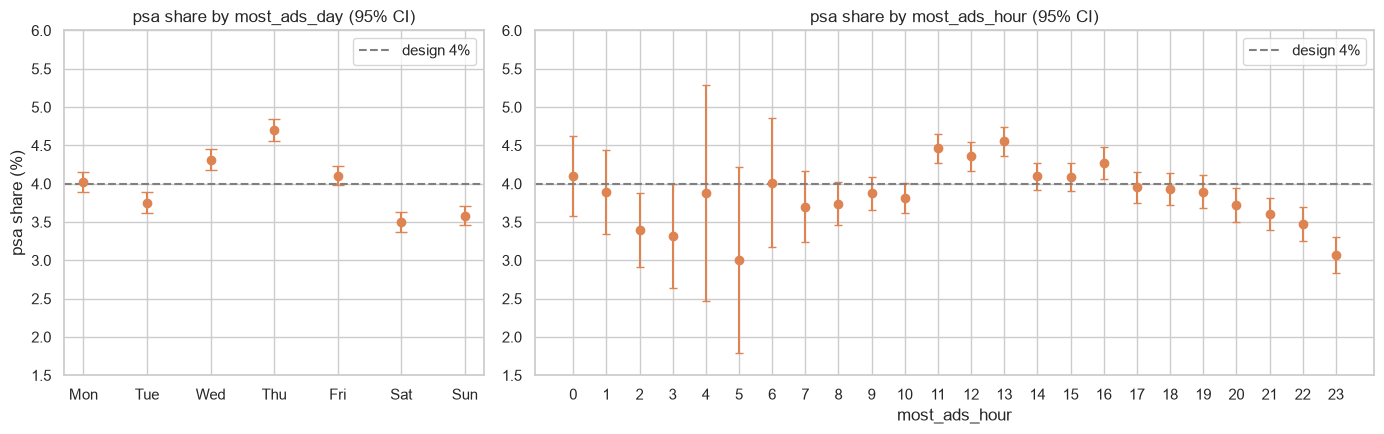

요일별 95% 신뢰구간 폭: ±0.12 ~ ±0.14%p
시간대별 95% 신뢰구간 폭: ±0.18%p (14시) ~ ±1.41%p (4시)

신뢰구간이 4%를 포함하지 않는 요일: 5개 / 7개 → ['Tue', 'Wed', 'Thu', 'Sat', 'Sun']
신뢰구간이 4%를 포함하지 않는 시간대: 9개 / 24개 → [2, 11, 12, 13, 16, 20, 21, 22, 23]


In [15]:
# [1-5-③] 세그먼트별 배정 비율 그래프: 요일·시간대별 psa 비율과 95% 신뢰구간
def share_ci(ct):
    p = ct["psa"] / ct["total"]                         # psa 비율 (0~1)
    se = np.sqrt(p * (1 - p) / ct["total"])             # 표준오차
    return p * 100, 1.96 * se * 100                     # 비율(%)과 95% 신뢰구간 폭(%p)

day_p, day_err = share_ci(day_ct)
hour_p, hour_err = share_ci(hour_ct)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})

axes[0].errorbar(day_ct.index.str[:3], day_p, yerr=day_err, fmt="o", capsize=4, color="C1")
axes[0].axhline(4, color="gray", ls="--", label="design 4%")
axes[0].set_ylim(1.5, 6)
axes[0].set_ylabel("psa share (%)")
axes[0].set_title("psa share by most_ads_day (95% CI)")
axes[0].legend()

axes[1].errorbar(hour_ct.index, hour_p, yerr=hour_err, fmt="o", capsize=3, color="C1")
axes[1].axhline(4, color="gray", ls="--", label="design 4%")
axes[1].set_ylim(1.5, 6)
axes[1].set_xticks(range(24))
axes[1].set_xlabel("most_ads_hour")
axes[1].set_title("psa share by most_ads_hour (95% CI)")
axes[1].legend()

plt.tight_layout()
plt.show()

# 신뢰구간 폭과, 신뢰구간이 설계 비율 4%를 포함하지 않는 세그먼트
print(f"요일별 95% 신뢰구간 폭: ±{day_err.min():.2f} ~ ±{day_err.max():.2f}%p")
print(f"시간대별 95% 신뢰구간 폭: ±{hour_err.min():.2f}%p ({hour_err.idxmin()}시) ~ ±{hour_err.max():.2f}%p ({hour_err.idxmax()}시)")

day_out = (day_p - day_err > 4) | (day_p + day_err < 4)       # 신뢰구간 전체가 4%보다 위 또는 아래
hour_out = (hour_p - hour_err > 4) | (hour_p + hour_err < 4)
print(f"\n신뢰구간이 4%를 포함하지 않는 요일: {day_out.sum()}개 / 7개 → {day_ct.index[day_out].str[:3].tolist()}")
print(f"신뢰구간이 4%를 포함하지 않는 시간대: {hour_out.sum()}개 / 24개 → {hour_ct.index[hour_out].tolist()}")

**결과 해석**

- **요일 :** 요일마다 인원이 8만~9만 명이라 신뢰구간이 ±0.12~0.14%p로 좁습니다. 7개 중 **5개 요일**(화·수·목·토·일)은 신뢰구간이 4%를 포함하지 않아, psa 비율이 4%와 확실히 다릅니다. 수·목은 4%보다 높고, 화·토·일은 낮습니다.

- **시간대 :** 새벽(2~6시)은 인원이 적어 신뢰구간이 매우 넓습니다(4시 ±1.41%p). 낮(9~19시)은 인원이 많아 좁습니다(14시 ±0.18%p). 24개 중 **9개 시간대**가 4%와 확실히 다르며, **낮(11~13시, 16시)은 높고 밤(20~23시)은 낮은** 흐름이 뚜렷합니다.

- **신뢰구간의 역할 :** 5시(3.01%)와 23시(3.07%)는 비율이 비슷하게 낮지만, 5시는 인원이 적어 신뢰구간이 4%를 포함하고 23시는 포함하지 않습니다. **같은 비율이라도 인원에 따라 판단이 달라지므로**, 비율만 보지 않고 신뢰구간을 함께 봐야 합니다.

---

**📝 1-5 세그먼트별 배정 비율 점검 정리**

| 점검 | 결과 | 판단 |
| --- | --- | --- |
| 1-5-① 요일 | χ²(6) = 235.6, p = 4.85e-48, V = 0.020 | 유의하지만 효과 매우 작음 |
| 1-5-② 시간대 | χ²(23) = 192.3, p = 1.09e-28, V = 0.018 | 유의하지만 효과 매우 작음 |
| 1-5-③ 그래프 | 요일 5/7개, 시간대 9/24개가 4%와 확실히 다름 | 낮에 높고 밤에 낮은 규칙적인 흐름 |

- **판단 :** 요일·시간대별 psa 비율은 4%에서 통계적으로 유의하게 벗어나지만, 효과 크기는 매우 작습니다. `most_ads_day`와 `most_ads_hour`는 **배정 이후의 행동으로 정해지는 변수**이고, 하루의 흐름을 따르는 규칙적인 모양은 배정 오류보다는 **광고와 공익광고의 송출 일정 차이**로 보는 것이 자연스럽습니다.

- **조치 :** 데이터는 지우지 않습니다. 다만 **5단계에서 요일·시간대별로 전환율을 비교할 때**, 세그먼트마다 두 그룹의 구성 비율이 다르고 새벽 시간대는 psa 인원이 수십 명뿐이라는 점을 고려합니다. 송출 일정을 확인할 수 없다는 점은 **6. 한계**에 적습니다.

**정제 전후: 588,101행 → 588,101행 (제거한 행 없음).**

### 1-6. 노출량 균형

무작위 배정이 잘 되었다면 두 그룹은 **비슷한 사람들**로 이루어져 있어야 합니다. 그래서 두 그룹이 본 광고 수(`total_ads`)의 분포가 비슷한지 확인합니다.

만약 광고 그룹이 공익광고 그룹보다 광고를 훨씬 많이 봤다면, 나중에 전환율 차이가 나왔을 때 "광고 **내용** 때문인지, 광고를 **더 많이 봐서**인지" 구분하기 어려워집니다.

> 💡 `total_ads`도 1-5의 요일·시간대처럼 **배정 이후에 정해지는 변수**입니다. 그래서 이 점검은 "배정이 공정했는가"를 직접 증명하지는 못하고, **"두 그룹의 노출 조건이 비슷했는가"**를 확인하는 보조 점검입니다.

| 번호 | 제목 | 확인하는 것 |
| --- | --- | --- |
| 1-6-① | 그룹별 노출량 요약 통계 비교 | 두 그룹의 평균·중앙값·사분위수가 비슷한가 |
| 1-6-② | 노출량 차이 검정과 효과 크기 | 차이가 통계적으로 유의한가, 실제로 의미 있는 크기인가 |
| 1-6-③ | 그룹별 노출량 분포 그래프 | 두 그룹의 분포 모양이 겹치는가 |

#### ① 그룹별 노출량 요약 통계 비교

1-1-⑤에서 전체 사용자의 `total_ads` 요약 통계를 봤습니다. 이번에는 **그룹별로 나눠서** 같은 통계를 나란히 비교합니다.

In [16]:
# [1-6-①] 그룹별 노출량 요약 통계 비교: 두 그룹이 본 광고 수가 비슷한가
summary = df.groupby("group")["total_ads"].describe()            # 그룹별 요약 통계
summary = summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

print(summary.round(2).to_string())
print()
print(f"평균 차이 (ad - psa): {summary.loc['ad', 'mean'] - summary.loc['psa', 'mean']:.2f}개")
print(f"중앙값 차이 (ad - psa): {summary.loc['ad', '50%'] - summary.loc['psa', '50%']:.0f}개")

            count    mean     std    min    25%     50%     75%       max
group                                                                    
ad    564577.0000 24.8200 43.7500 1.0000 4.0000 13.0000 27.0000 2065.0000
psa    23524.0000 24.7600 42.8600 1.0000 4.0000 12.0000 26.0000  907.0000

평균 차이 (ad - psa): 0.06개
중앙값 차이 (ad - psa): 1개


**결과 해석**

- **결과 :** 평균(24.82 vs 24.76, 차이 0.06개), 표준편차(43.75 vs 42.86), 사분위수(4 / 13 / 27 vs 4 / 12 / 26)가 거의 같습니다. **두 그룹은 광고를 비슷한 양만큼, 비슷하게 퍼진 모양으로 봤습니다.**

- **최댓값 차이 :** 최댓값은 ad 2,065개, psa 907개로 크게 다르지만, 이는 그룹 크기가 24배 달라서 생긴 차이입니다. 인원이 많을수록 드문 극단값이 나올 기회도 많아지기 때문입니다. 그래서 그룹 비교에는 최댓값보다 **중앙값과 사분위수**를 씁니다.

- **다음 단계 :** 숫자로는 두 그룹의 노출량이 실질적으로 같아 보입니다. 중앙값 1개 차이가 우연인지는 1-6-②에서 검정합니다.

#### ② 노출량 차이 검정과 효과 크기

1-6-①에서 두 그룹의 중앙값이 1개 차이 났습니다. 이 차이가 우연인지 **Mann-Whitney U 검정**으로 확인하고, 차이가 실제로 얼마나 큰지 **효과 크기**로 함께 봅니다.

`total_ads`는 오른쪽 꼬리가 매우 긴 분포(1-1-⑤)라서, 평균을 비교하는 t-검정보다 **순위를 비교하는 Mann-Whitney U 검정**이 적합합니다.

In [17]:
# [1-6-②] 노출량 차이 검정과 효과 크기: 중앙값 1개 차이가 우연인가, 의미 있는 크기인가
ads_ad  = df.loc[df["group"] == "ad",  "total_ads"]       # 광고 그룹의 본 광고 수
ads_psa = df.loc[df["group"] == "psa", "total_ads"]       # 공익광고 그룹의 본 광고 수

mw = stats.mannwhitneyu(ads_ad, ads_psa, alternative="two-sided")

n1, n2 = len(ads_ad), len(ads_psa)
prob_sup = mw.statistic / (n1 * n2)        # 우월 확률: ad 사용자가 psa 사용자보다 더 많이 봤을 확률
r_rb = 2 * prob_sup - 1                    # 효과 크기: rank-biserial r

print(f"Mann-Whitney U 검정: U = {mw.statistic:,.0f}, p = {mw.pvalue:.2e}")
print(f"우월 확률 P(ad > psa) = {prob_sup:.3f}  (0.5면 두 그룹이 같음)")
print(f"효과 크기 rank-biserial r = {r_rb:.3f}  (0이면 차이 없음, ±1이면 완전히 다름)")

Mann-Whitney U 검정: U = 6,808,288,222, p = 4.69e-11
우월 확률 P(ad > psa) = 0.513  (0.5면 두 그룹이 같음)
효과 크기 rank-biserial r = 0.025  (0이면 차이 없음, ±1이면 완전히 다름)


**결과 해석**

- **검정 선택 :** `total_ads`는 오른쪽 꼬리가 매우 긴 분포라서, 평균을 비교하는 t-검정 대신 극단값의 영향을 덜 받는 **Mann-Whitney U 검정**을 썼습니다.

- **p값 :** p = 4.69e-11로 0.05보다 훨씬 작습니다. 두 그룹의 노출량 분포가 완전히 같다고 보기는 어렵습니다.

- **효과 크기 :** 우월 확률 0.513, rank-biserial r = 0.025입니다. ad 사용자와 psa 사용자를 한 명씩 뽑으면 ad 쪽이 더 많이 봤을 확률이 51.3%로, 동전 던지기(50%)와 거의 같습니다. **무시할 만한 크기**입니다.

| 지표 | 말해 주는 것 | 결과 |
| --- | --- | --- |
| p값 | 차이가 우연이 아닌가 | 우연이 아님 (p = 4.69e-11) |
| 효과 크기 | 차이가 얼마나 큰가 | 거의 0 (r = 0.025) |

- **판단 :** 표본이 59만 명이라 아주 미세한 차이도 유의하게 나왔을 뿐, **두 그룹의 노출 조건은 실질적으로 같습니다.** 나중에 전환율 차이가 나오더라도 "광고를 더 많이 봐서"라고 설명하기 어려우므로, 광고 내용의 차이로 해석할 근거가 됩니다.

#### ③ 그룹별 노출량 분포 그래프

두 그룹의 `total_ads` 분포를 겹쳐 그려, 모양이 얼마나 겹치는지 눈으로 확인합니다. 그룹 크기가 24배 다르므로 **인원 수가 아니라 비율**로 맞춰서 비교합니다.

- **왼쪽 (히스토그램):** 구간별로 사용자가 얼마나 몰려 있는지
- **오른쪽 (누적 분포, ECDF):** 광고를 x개 이하로 본 사용자가 전체의 몇 %인지

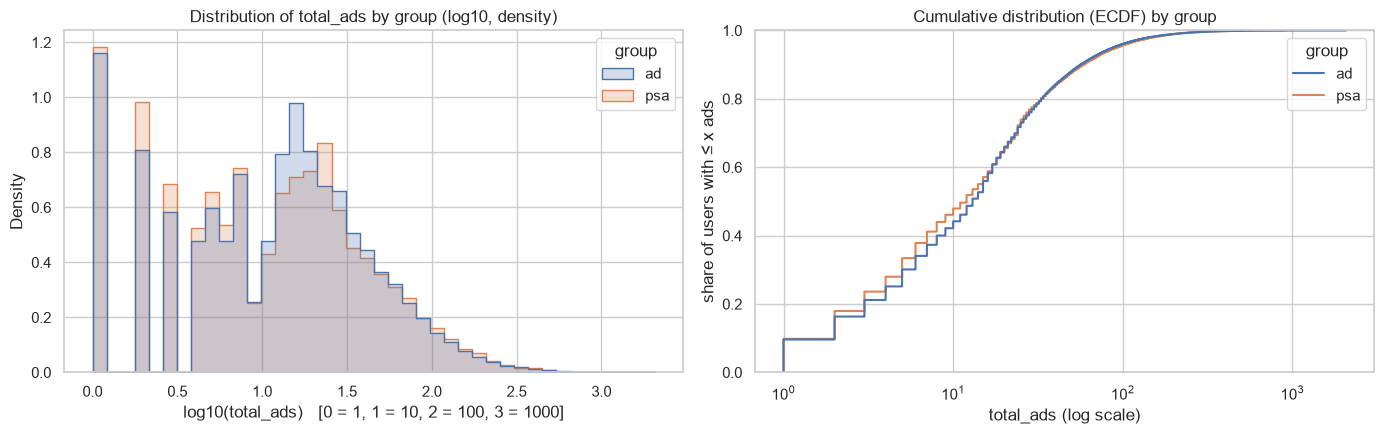

▶ 같은 백분위수에서 두 그룹이 본 광고 수
          ad      psa  차이(ad-psa)
10%   2.0000   2.0000      0.0000
25%   4.0000   4.0000      0.0000
50%  13.0000  12.0000      1.0000
75%  27.0000  26.0000      1.0000
90%  56.0000  59.0000     -3.0000
99% 201.0000 206.0000     -5.0000


In [18]:
# [1-6-③] 그룹별 노출량 분포 그래프: 두 그룹의 분포 모양이 겹치는가
plot_df = df[["group", "total_ads"]].copy()
plot_df["log10_total_ads"] = np.log10(plot_df["total_ads"])            # 꼬리가 길어 로그 척도로 봄

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (왼쪽) 히스토그램: 그룹마다 따로 비율로 맞춰서 겹쳐 그리기
sns.histplot(data=plot_df, x="log10_total_ads", hue="group", bins=40,
             stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Distribution of total_ads by group (log10, density)")
axes[0].set_xlabel("log10(total_ads)   [0 = 1, 1 = 10, 2 = 100, 3 = 1000]")

# (오른쪽) 누적 분포(ECDF): x개 이하로 본 사용자의 비율
sns.ecdfplot(data=plot_df, x="total_ads", hue="group", log_scale=True, ax=axes[1])
axes[1].set_title("Cumulative distribution (ECDF) by group")
axes[1].set_xlabel("total_ads (log scale)")
axes[1].set_ylabel("share of users with ≤ x ads")

plt.tight_layout()
plt.show()

# 같은 백분위수에서 두 그룹의 값 비교
qs = [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
q_table = pd.DataFrame({
    "ad":  ads_ad.quantile(qs).values,
    "psa": ads_psa.quantile(qs).values,
}, index=[f"{q:.0%}" for q in qs])
q_table["차이(ad-psa)"] = q_table["ad"] - q_table["psa"]
print("▶ 같은 백분위수에서 두 그룹이 본 광고 수")
print(q_table.to_string())

**결과 해석**

- **히스토그램 (왼쪽) :** 그룹마다 따로 비율로 맞춰 겹쳐 그렸습니다(`common_norm=False`). 두 그룹의 봉우리 위치와 꼬리 모양이 거의 같습니다. 왼쪽 끝이 들쭉날쭉한 것은 광고 수가 정수라서 로그 변환 후 값 사이에 빈 구간이 생기기 때문이며, 데이터 문제가 아닙니다.

- **누적 분포 (오른쪽) :** 두 선이 처음부터 끝까지 거의 완전히 겹칩니다. 광고 3~20개 구간에서 아주 작은 틈이 있는데, 이것이 1-6-①의 중앙값 1개 차이입니다.

- **백분위수 비교 :** 하위 구간(10%, 25%)은 같고, 중간(50%, 75%)은 ad가 1개 많고, 상위(90%, 99%)는 오히려 psa가 3~5개 많습니다. **차이의 방향이 섞여 있어**, 어느 한쪽이 체계적으로 광고를 더 많이 봤다고 볼 수 없습니다.

---

**📝 1-6 노출량 균형 정리**

| 점검 | 결과 | 판단 |
| --- | --- | --- |
| 1-6-① 요약 통계 | 평균 차이 0.06개, 중앙값 차이 1개 | 거의 같음 |
| 1-6-② Mann-Whitney U | p = 4.69e-11, r = 0.025, 우월 확률 0.513 | 유의하지만 효과는 무시할 만한 크기 |
| 1-6-③ 분포 그래프 | 두 분포가 거의 겹침, 차이 방향이 섞여 있음 | 체계적인 차이 없음 |

- **판단 :** 두 그룹이 본 광고 수는 **실질적으로 같습니다.** 나중에 전환율 차이가 나오더라도 "광고를 더 많이 봐서"라고 설명하기 어려우므로, **광고 내용의 차이**로 해석할 근거가 됩니다.

- **주의 :** `total_ads`는 배정 이후에 정해지는 변수라, 이 결과가 배정의 공정성을 직접 증명하지는 않습니다. 두 그룹의 **노출 조건이 비슷했다**는 보조 근거입니다.

**정제 전후: 588,101행 → 588,101행 (제거한 행 없음).**

### 1-7. 정제 결과와 데이터 점검 메모

1-1부터 1-6까지의 점검을 마무리합니다. 정제 전후로 무엇이 바뀌었는지 확인하고, 모든 점검 결과를 한 표로 정리합니다.

| 번호 | 제목 | 확인하는 것 |
| --- | --- | --- |
| 1-7-① | 정제 전후 비교와 최종 확인 | 행·열 변화, 핵심 조건 자동 확인 |
| 1-7-② | 데이터 점검 메모 | 1-1~1-6 결과 요약 |

#### ① 정제 전후 비교와 최종 확인

원본 `raw`와 정제한 `df`를 나란히 비교하고, 검정에 들어가기 전 꼭 지켜져야 할 조건 네 가지를 `assert`로 자동 확인합니다.

In [19]:
# [1-7-①] 정제 전후 비교와 최종 확인
N_CLEAN = len(df)

print(f"정제 전 (raw): {N_RAW:,}행 × {raw.shape[1]}열")
print(f"정제 후 (df) : {N_CLEAN:,}행 × {df.shape[1]}열")
print(f"제거된 행: {N_RAW - N_CLEAN:,}개 / 제거된 열: {raw.shape[1] - df.shape[1]}개")
print()
print("정제 전 컬럼:", raw.columns.tolist())
print("정제 후 컬럼:", df.columns.tolist())

# 최종 확인: 조건이 하나라도 틀리면 여기서 오류(AssertionError)가 나고 멈춥니다
assert N_CLEAN == N_RAW                              # 행 손실 없음
assert df.isna().sum().sum() == 0                     # 결측치 0개
assert df["user_id"].is_unique                        # 한 사람 = 한 행
assert set(df["group"].unique()) == {"ad", "psa"}     # 그룹 라벨은 ad, psa 두 가지뿐

print()
print("✅ 최종 확인 통과: 행 손실 없음 / 결측치 0개 / user_id 고유 / 그룹 라벨 ad·psa")

정제 전 (raw): 588,101행 × 7열
정제 후 (df) : 588,101행 × 6열
제거된 행: 0개 / 제거된 열: 1개

정제 전 컬럼: ['Unnamed: 0', 'user id', 'test group', 'converted', 'total ads', 'most ads day', 'most ads hour']
정제 후 컬럼: ['user_id', 'group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']

✅ 최종 확인 통과: 행 손실 없음 / 결측치 0개 / user_id 고유 / 그룹 라벨 ad·psa


**결과 해석**

- **행 :** 588,101개 → 588,101개로, 1단계 전체에서 **사용자를 한 명도 지우지 않았습니다.** 정제 과정 때문에 결과가 왜곡될 걱정이 없습니다.

- **열 :** 7개 → 6개입니다. 행 번호가 저장된 `Unnamed: 0`을 삭제했고, 나머지는 이름만 바꿨습니다.

- **최종 확인 :** 행 손실 없음, 결측치 0개, `user_id` 고유, 그룹 라벨 두 가지의 네 조건을 `assert`로 확인했고 모두 통과했습니다. 다른 데이터로 다시 실행했을 때 조건이 깨지면, 이 셀에서 오류가 나며 멈춰 **오염된 데이터로 검정하는 것을 막아 줍니다.**

#### ② 데이터 점검 메모

| 단계 | 점검 항목 | 결과 | 조치와 이유 |
| --- | --- | --- | --- |
| 1-1 | 행 수 / 컬럼 | 588,101행 × 7열 | — |
| 1-1 | 결측치 | 0개 | 없음 |
| 1-1 | `Unnamed: 0` | 행 번호와 588,101개 모두 같음 | **컬럼 삭제.** 저장 과정에서 생긴 불필요한 컬럼 |
| 1-1 | 컬럼 이름 | 공백 포함 | 밑줄로 바꿈 (snake_case) |
| 1-1 | 값의 범위 | 다섯 가지 점검 모두 통과 | 없음 |
| 1-1 | `total_ads` 극단값 | 최대 2,065개, 오른쪽 꼬리가 긴 분포 | **유지.** 하나로 이어진 분포라 실제 헤비 유저일 가능성이 높고, 주 지표가 아님 |
| 1-2 | 완전 중복 행 | 0개 | 없음 |
| 1-2 | `user_id` 중복 | 0개 (고유 588,101명 = 전체 588,101행) | 없음. 한 사람 = 한 행 |
| 1-3 | 두 그룹 동시 배정 | 0명 | 없음 |
| 1-3 | 그룹 라벨 표기 | `'ad'`, `'psa'` 두 가지, 공백·대소문자 차이 0개 | 없음 |
| 1-4 | SRM (50:50 기대) | χ² = 497,768.8, p ≈ 0 | 이 실험의 설계와 맞지 않는 기대 비율이라 **쓰지 않음** |
| 1-4 | SRM (96:4 기대, 추정 설계 비율) | χ² ≈ 0, p = 0.9998 | ✅ 정상 |
| 1-5 | 요일·시간대별 psa 비율 | 유의하게 다름 (V = 0.018~0.020) | **유지.** 배정 이후 행동 변수이고 효과 크기가 매우 작음. 세그먼트 분석 시 주의 |
| 1-6 | 노출량 균형 | 유의하지만 효과 무시할 만함 (r = 0.025) | 없음. 두 그룹의 노출 조건은 실질적으로 같음 |

**정제 전후 : 588,101행 × 7열 → 588,101행 × 6열 (행 삭제 0개, 컬럼 삭제 1개)**

**결론 :** 중복, 배정 불일치, SRM 문제가 없어 **검정에 쓸 수 있는 데이터**입니다.

**6. 한계에 옮겨 적을 항목**

- 96:4는 설계 문서로 확인한 비율이 아니라, 데이터셋 설명과 관측 비율에서 **추정한 값**이다.
- psa 비율이 4%에 가장 가까운 정수로 정확히 떨어져, 데이터가 어떻게 배정·추출되었는지 알 수 없다.
- 요일·시간대별 psa 비율 차이가 송출 일정 때문인지 확인할 수 없다.
- `most_ads_day`, `most_ads_hour`, `total_ads`는 배정 이후에 정해지는 변수라, 이 변수로 나눈 분석은 인과적으로 해석하기 어렵다.

## 2. 질문과 가설

> ⚠️ 이 단계는 **그룹별 전환율을 보기 전에** 작성합니다. 결과를 본 뒤 가설, 검정, 유의수준을 바꾸면 p-해킹이 됩니다. 여기서 정한 것은 끝까지 유지합니다.
>
> 1-1-④에서 확인한 **전체** 전환율(2.52%)은 그룹을 나누지 않은 숫자라 가설 설정에 영향을 주지 않습니다.

| 번호 | 제목 |
| --- | --- |
| 2-1 | 알고 싶은 것 |
| 2-2 | 성공 지표와 비교 대상 |
| 2-3 | 가설 |
| 2-4 | 유의수준과 검정 방향 |
| 2-5 | 사전 결정 기록 |
| 2-6 | 사전 결정 정리 |

### 2-1. 알고 싶은 것

내가 이 분석으로 무엇을 알고 싶은지, 왜 알고 싶은지, 그것을 데이터로 어떻게 확인할지 정합니다.

| 번호 | 제목 | 답하는 것 |
| --- | --- | --- |
| 2-1-① | 질문의 세 단계 | **무엇을** 알고 싶은가 |
| 2-1-② | 내려야 할 결정 | **왜** 알고 싶은가 |
| 2-1-③ | 검정 질문으로 바꾼 이유 | 왜 **그렇게** 바꿨나 |
| 2-1-④ | 이 실험이 재는 것과 가정 | 결과를 **어디까지** 해석할 수 있나 |

#### ① 질문의 세 단계

처음 궁금했던 것을 **점점 구체적인 말**로 바꿔 세 단계로 적습니다. 세 문장은 같은 것을 묻고 있고, 아래로 갈수록 데이터로 답하기 쉬운 형태가 됩니다.

| 단계 | 표현 | 역할 |
| --- | --- | --- |
| **분석 목적** | 소비자의 구매 성향이 광고로 인해 작용하는가? | 처음 궁금했던 것 |
| **분석 질문** | 공익광고 대신 우리 광고를 보여 주면, 사는 사람이 더 많아질까(또는 적어질까)? | 누구나 이해할 수 있는 쉬운 말 |
| **검정 질문** | **광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 다른가?** | 데이터로 검정할 수 있는 정확한 말 |

이 분석은 **검정 질문**에 답합니다.

| 구성 요소 | 분석 목적 | → | 분석 질문 | → | 검정 질문 |
| --- | --- | :---: | --- | :---: | --- |
| **무엇이 (결과)** | 소비자의 구매 성향 | → | 사는 사람 | → | **구매 전환율** |
| **무엇 때문에 (원인)** | 광고로 인해 | → | 공익광고 대신 우리 광고를 보여 주면 | → | **광고를 본 사용자 vs 공익광고를 본 사용자** |
| **어떻게 되는가 (판단)** | 작용하는가? | → | 더 많아질까(또는 적어질까)? | → | **다른가?** |

#### ② 내려야 할 결정

**"이 광고 캠페인에 계속 비용을 쓸 것인가?"**

검정 질문의 답이 이 결정으로 어떻게 이어지는지 미리 정해 둡니다.

| 검정 결과 | 뜻 | 이어지는 결정 (6단계에서 최종 판단) |
| --- | --- | --- |
| 광고 그룹의 전환율이 **유의하게 높음** | 광고가 공익광고보다 구매를 더 이끌어 냄 | 캠페인 **계속** 검토 (효과 크기와 비용도 함께 고려) |
| 광고 그룹의 전환율이 **유의하게 낮음** | 광고가 오히려 구매를 줄임 | 캠페인 **중단** 검토 |
| **유의한 차이 없음** | 다르다는 증거가 부족함 | 효과가 없다고 단정하지 않고, 이 표본으로 잡을 수 있는 최소 효과(MDE)를 확인한 뒤 **보류 또는 추가 수집** 검토 |

> 💡 결과를 본 뒤 결정 기준을 정하면 원하는 결론에 맞추게 될 수 있으므로, **결과를 보기 전에** 세 가지 경우를 모두 정해 둡니다.

#### ③ 검정 질문으로 바꾼 이유

분석 목적을 이 데이터로 검정할 수 있도록 세 가지 말을 바꿨습니다.

| 분석 목적의 말 | 검정 질문의 말 | 바꾼 이유 |
| --- | --- | --- |
| 구매 **성향** | 구매 **전환율** | 데이터에는 사람의 성향(마음, 특성)이 아니라 **실제로 샀는지**(`converted`)만 기록됨 |
| **작용**하는가 | 전환율이 **다른가** | "작용"은 뜻이 넓어 측정할 수 없으므로, **두 그룹의 전환율 비교**라는 측정 가능한 형태로 바꿈 |
| **광고**로 인해 | 광고를 본 사용자 **vs 공익광고를 본 사용자** | 대조군은 광고를 안 본 사람이 아니라 **공익광고를 본 사람**이므로, 비교 대상을 정확히 밝힘 |

따라서 이 분석은 "소비자의 성향이 바뀌었는가"가 아니라, **"광고가 공익광고와 비교해 실제로 구매하는 사람의 비율을 바꾸는가"**에 답합니다.

분석 목적을 이 데이터로 검정할 수 있도록 세 가지 말을 바꿨습니다. 이렇게 추상적인 개념을 **측정 가능한 형태로 정의하는 것**을 **조작적 정의(operational definition)**라고 합니다.

#### ④ 이 실험이 재는 것과 가정

**이 실험이 재는 것 :** 일반광고와 공익광고의 영향을 **각각 따로** 재는 것이 아니라, **두 그룹의 전환율 차이 하나**를 잽니다. 광고를 아무것도 안 본 그룹이 없기 때문입니다.

$$\text{이 실험이 재는 것} = p_{ad} - p_{psa}$$

| 그룹 | 이 실험에 있나 | 알 수 있는 것 |
| --- | --- | --- |
| 일반광고 (ad) | ✅ | 전환율 |
| 공익광고 (psa) | ✅ | 전환율 |
| 광고 없음 | ❌ | 알 수 없음 |

**필요한 가정 :** 이 차이를 **일반광고의 효과**로 해석하려면 아래 가정이 필요합니다.

> **"공익광고는 회사 상품 구매에 영향을 주지 않는다."**

| 가정이 맞으면 | 가정이 틀리면 |
| --- | --- |
| 공익광고 그룹은 사실상 "광고 없음" 그룹 역할을 함 | 공익광고도 구매에 어떤 영향을 줌 |
| 두 그룹의 차이 = **일반광고의 효과** | 두 그룹의 차이 = 일반광고 효과와 공익광고 효과가 **섞인 값** |

이 가정은 이 데이터로 확인할 수 없으므로 **6. 한계**에 적습니다.

### 2-2. 성공 지표와 비교 대상

검정 질문 **"광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 다른가?"**를 검정하기 위해, 무엇으로 누구와 누구를 비교할지 정합니다.

| 항목 | 내용 |
| --- | --- |
| 성공 지표 | `converted` (구매 여부) |
| 지표 형태 | **비율** (전환한 사람 ÷ 전체) |
| 실험군 | `ad` (광고를 본 그룹) |
| 대조군 | `psa` (공익광고를 본 그룹) |
| 분석 단위 | 사용자 1명 = 1행 |

**이렇게 정한 이유**

- **성공 지표 :** 분석 목적의 "구매 성향"을 데이터에서 가장 가깝게 나타내는 값입니다 (2-1-③).
- **지표 형태 :** `converted`가 True/False 값이므로 전환율(비율)로 비교합니다.
- **실험군 / 대조군 :** 광고를 본 그룹이 처치를 받은 그룹이고, 공익광고를 본 그룹이 비교 기준입니다.
- **분석 단위 :** 한 사람이 한 행으로만 기록되어 있습니다 (1-2).

**주 지표로 쓰지 않는 변수**

- `total_ads` : 배정 이후 사용자 행동으로 정해지는 값입니다 (1-6).
- `most_ads_day`, `most_ads_hour` : 배정 이후 사용자 행동으로 정해지는 값입니다 (1-5). 5단계 보조 분석에서만 사용합니다.

### 2-3. 가설

- $p_{ad}$ : 광고 그룹의 구매 전환율
- $p_{psa}$ : 공익광고 그룹의 구매 전환율

| 가설 | 수식 |
| --- | --- |
| 귀무가설 $H_0$ | $p_{ad} = p_{psa}$ |
| 대립가설 $H_1$ | $p_{ad} \neq p_{psa}$ |

**귀무가설 $H_0$ :** 광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 **같다.**
→ 광고로 인해 구매가 달라지지 않는다.

**대립가설 $H_1$ :** 광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 **다르다.**
→ 광고로 인해 구매가 달라진다.

데이터가 귀무가설과 크게 어긋나면(p < α) 귀무가설을 기각하고 대립가설을 받아들입니다.

> 💡 p ≥ α가 나오면 "두 그룹은 같다"가 아니라 **"다르다는 증거가 부족하다"**로 해석합니다.

### 2-4. 유의수준과 검정 방향

| 항목 | 결정 |
| --- | --- |
| 유의수준 | α = 0.05 |
| 검정 방향 | 양측 검정 (two-sided) |

**유의수준 α = 0.05**

p값이 0.05보다 작으면 귀무가설을 기각합니다. 즉 "두 그룹의 전환율이 같다면 이만큼 차이가 날 확률이 5% 미만"일 때 차이가 있다고 판단합니다. 가장 널리 쓰는 기준이고, 이 실험에서 더 엄격하거나 느슨하게 정할 특별한 이유가 없습니다.

**검정 방향 : 양측 검정**

분석 질문이 **"사는 사람이 더 많아질까(또는 적어질까)?"**이므로 양쪽 방향을 모두 봅니다.

| 구분 | 단측 검정 | 양측 검정 ✅ |
| --- | --- | --- |
| 대립가설 | $p_{ad} > p_{psa}$ | $p_{ad} \neq p_{psa}$ |
| 잡아내는 경우 | 광고가 더 좋을 때만 | 더 좋을 때와 나쁠 때 모두 |

양측 검정을 고른 이유는 두 가지입니다.

1. **광고가 오히려 역효과일 가능성도 확인해야 합니다.**

### 2-5. 사전 결정 기록

2-1 ~ 2-4에서 정한 것을 변수로 고정합니다. 이후 모든 코드는 이 변수를 그대로 사용하고, **값을 바꾸지 않습니다.**

> 💡 **이유 :** 기준이 코드 곳곳에 흩어져 있으면, 결과를 본 뒤 유의수준이나 검정 방향을 슬쩍 바꿔도 드러나지 않습니다(p-해킹). 기준을 이 셀 한 곳에 모아 두면, 바꾸려면 이 셀을 고쳐야 하므로 **결과를 본 뒤 기준을 바꾼 흔적이 분명히 남습니다.**

In [20]:
# [2-5] 사전 결정 기록: 그룹별 전환율을 보기 전에 정한 분석 설정 (이후 변경하지 않음)
RESEARCH_QUESTION = "광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 다른가?"
PRIMARY_METRIC = "converted"     # 주 지표: 구매 전환 여부 (비율)
TREATMENT = "ad"                 # 실험군: 광고
CONTROL = "psa"                  # 대조군: 공익광고
ALPHA = 0.05                     # 유의수준
ALTERNATIVE = "two-sided"        # 검정 방향: 양측

print("📌 사전 결정 (이후 변경하지 않음)")
print(f"  검정 질문  : {RESEARCH_QUESTION}")
print(f"  주 지표    : {PRIMARY_METRIC} (구매 전환 여부, 비율)")
print(f"  비교       : {TREATMENT}(실험군) vs {CONTROL}(대조군)")
print(f"  유의수준 α : {ALPHA}")
print(f"  검정 방향  : {ALTERNATIVE} (양측)")

📌 사전 결정 (이후 변경하지 않음)
  검정 질문  : 광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 다른가?
  주 지표    : converted (구매 전환 여부, 비율)
  비교       : ad(실험군) vs psa(대조군)
  유의수준 α : 0.05
  검정 방향  : two-sided (양측)


### 2-6. 사전 결정 정리

**질문**

- **분석 목적 :** 소비자의 구매 성향이 광고로 인해 작용하는가?
- **검정 질문 :** 광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 다른가?
- **내려야 할 결정 :** 이 광고 캠페인에 계속 비용을 쓸 것인가?

**검정 설정**

| 항목 | 결정 |
| --- | --- |
| 주 지표 | `converted` (구매 전환율) |
| 비교 | `ad` vs `psa` |
| 귀무가설 | $p_{ad} = p_{psa}$ |
| 대립가설 | $p_{ad} \neq p_{psa}$ |
| 유의수준 | α = 0.05 |
| 검정 방향 | 양측 |

**필요한 가정 :** 공익광고는 회사 상품 구매에 영향을 주지 않는다 (2-1-④).

이 결정은 3단계 이후 **바꾸지 않습니다.**

## 3. 검정 고르기

> ⚠️ 3단계에서도 **그룹별 전환율은 계산하지 않습니다.** 검정의 가정은 그룹별 결과를 보지 않는 방법으로 확인합니다.

| 번호 | 제목 | 하는 일 |
| --- | --- | --- |
| 3-1 | 검정을 정하는 세 가지 질문 | 검정 후보 고르기 |
| 3-2 | 검정 가정 확인 | 가정이 맞는지 확인 |
| 3-3 | 검정 선택 근거 | 왜 이 검정인가 |

### 3-1. 검정을 정하는 세 가지 질문

| 질문 | 답 |
| --- | --- |
| ① 지표가 비율인가, 연속형인가? | **비율** |
| ② 집단이 2개인가, 3개 이상인가? | **2개** |
| ③ 연속형이라면 정규성·등분산은? | **해당 없음** |

- **① 비율 :** `converted`는 True/False 값이고, 비교할 지표는 전환율(전환한 사람 ÷ 전체)입니다 (2-2).
- **② 2개 :** 광고 그룹(`ad`)과 공익광고 그룹(`psa`)을 비교합니다 (2-2).
- **③ 해당 없음 :** 정규성·등분산은 매출, 시간 같은 연속형 지표의 평균을 비교할 때 확인하는 가정입니다. 비율 지표에는 해당하지 않습니다.

**세 질문의 답을 차례로 대입하면**

| ① 지표 | ② 집단 수 | ③ 정규성 | 검정 |
| --- | --- | --- | --- |
| **비율** | **2개** | — | **카이제곱 / 두 비율 검정** ✅ |
| 비율 | 3개 이상 | — | 카이제곱 (R×C 표) |
| 연속형 | 2개 | OK | 2표본 t-검정 |
| 연속형 | 2개 | 위반 | Mann-Whitney U |
| 연속형 | 3개 이상 | — | 일원 ANOVA → Tukey |

왼쪽 열부터 차례로 답하면 맨 오른쪽 열의 검정이 정해집니다. 비율 지표는 ③ 정규성을 확인하지 않습니다(—).

이 실험은 **비율 · 2집단**(✅)이므로 **카이제곱 독립성 검정**이 후보입니다. 비율 지표의 검정에도 지켜야 할 가정이 있으므로, 3-2에서 확인합니다.

### 3-2. 검정 가정 확인

카이제곱 독립성 검정은 두 가지 가정이 지켜져야 결과를 믿을 수 있습니다.

| 가정 | 확인 방법 |
| --- | --- |
| ① 독립성 | 1-2에서 확인 (한 사람 = 한 행) |
| ② 기대 빈도 ≥ 5 | 이 셀에서 확인 |

**기대 빈도**는 "두 그룹의 전환율이 같다면(H₀) 각 칸에 나와야 할 인원"입니다. 같다면 두 그룹 모두 **전체 전환율**을 따라야 하므로, 아래처럼 계산합니다.

$$\text{기대 인원} = \text{그룹 인원} \times \text{전체 전환율}$$

그룹 인원(1-4)과 전체 전환율(1-1-④)은 이미 본 숫자이므로, **그룹별 전환율을 보지 않고** 가정을 확인할 수 있습니다.

In [21]:
# [3-2] 검정 가정 확인: 그룹별 전환율을 보지 않고, 카이제곱 검정의 조건이 맞는지 확인
N = len(df)
n_treat = (df["group"] == TREATMENT).sum()          # 실험군(ad) 인원
n_ctrl = (df["group"] == CONTROL).sum()             # 대조군(psa) 인원
n_conv_all = df[PRIMARY_METRIC].sum()               # 전체 전환 인원 (그룹 구분 없음)
p_pool = n_conv_all / N                             # 전체 전환율 (그룹 구분 없음)

# 두 그룹의 전환율이 같다면(H0) 각 칸에 나와야 할 기대 인원 = 그룹 인원 × 전체 전환율
expected = pd.DataFrame({
    "전환(True)":     [n_treat * p_pool,       n_ctrl * p_pool],
    "미전환(False)":  [n_treat * (1 - p_pool), n_ctrl * (1 - p_pool)],
}, index=[TREATMENT, CONTROL])

print(f"전체 전환율(그룹 구분 없음): {p_pool:.4%}")
print()
print("▶ 두 그룹의 전환율이 같다면 각 칸에 나와야 할 기대 인원")
print(expected.round(1).to_string())
print()
print(f"가장 작은 기대 인원: {expected.values.min():,.1f}명  (기준: 5명 이상)")

전체 전환율(그룹 구분 없음): 2.5239%

▶ 두 그룹의 전환율이 같다면 각 칸에 나와야 할 기대 인원
      전환(True)  미전환(False)
ad  14249.3000 550327.7000
psa   593.7000  22930.3000

가장 작은 기대 인원: 593.7명  (기준: 5명 이상)


**결과 해석**

| 가정 | 결과 | 판단 |
| --- | --- | --- |
| 독립성 | 한 사람 = 한 행 | ✅ |
| 기대 빈도 ≥ 5 | 최소 593.7명 | ✅ |

- **기대 빈도 :** 가장 작은 칸은 psa 그룹의 전환 칸으로 593.7명입니다. 전환율이 2.5%로 낮고 psa 그룹이 작지만, 기준(5명)을 100배 넘게 충족합니다. **카이제곱 검정을 그대로 쓸 수 있습니다.**
- **독립성 :** 1-2에서 한 사람이 한 번만 들어 있음을 확인했습니다. 다만 사용자끼리 서로의 구매에 영향을 줬을 가능성(예: 가족, 친구)은 데이터로 확인할 수 없어, 이 가정은 **6. 한계**에 적습니다.
- **결과를 미리 보지 않음 :** 그룹 인원과 전체 전환율만 썼으므로, 그룹별 전환율은 아직 모릅니다.

### 3-3. 검정 선택 근거

**나는 카이제곱 독립성 검정(2×2, 연속성 보정 없음)을 골랐다.** 왜냐하면 성공 지표인 `converted`는 구매 여부(True/False)라서 전환율이라는 **비율**로 비교해야 하고, 비교할 집단이 광고 그룹과 공익광고 그룹 **2개**이기 때문이다(3-1). 비율 지표는 0과 1 두 값뿐이라 평균을 비교하는 t-검정이나 Mann-Whitney U는 맞지 않고, 정규성·등분산 가정도 확인할 필요가 없다. 대신 카이제곱 검정에 필요한 두 가정을 확인했다. 한 사람이 한 행으로만 기록되어 **관측치가 독립**이고(1-2), 가장 작은 칸의 **기대 빈도가 593.7명**으로 기준(5명)을 크게 넘는다(3-2). 표본이 59만 명으로 매우 크므로 연속성 보정(Yates)은 결과에 거의 영향이 없어 적용하지 않았다. 이렇게 하면 두 비율 z-검정과 **같은 결과**(χ² = z²)가 나오므로, 4단계에서는 z-검정으로 **차이의 방향과 신뢰구간**을 함께 구한다.

**고르지 않은 검정과 이유**

- **2표본 t-검정, Mann-Whitney U :** 연속형 지표의 평균이나 순위를 비교하는 검정이라, 0/1 값인 전환 여부에는 맞지 않습니다.
- **피셔의 정확 검정 :** 칸의 인원이 적을 때(기대 빈도 5명 미만) 쓰는 검정입니다. 이 실험은 모든 칸이 충분히 커서 필요하지 않습니다.
- **단측 검정 :** 2-4에서 양측 검정으로 정했습니다.

**4단계에서 보고할 것 (미리 정함)**

| 구분 | 보고할 값 |
| --- | --- |
| 검정 | χ²(1), p값 |
| 점추정 | 전환율 차이 (%p) |
| 신뢰구간 | 차이의 95% 신뢰구간 |
| 효과 크기 | Cramér's V |
| 상대 차이 | 전환율 비율 (배수) |

비율 지표이므로 **절대 차이(%p)와 상대 차이(배수)를 둘 다** 보고합니다.

## 4. 검정 수행과 3종 세트 보고

2단계에서 정한 가설과 기준, 3-3에서 정한 보고 항목을 **그대로** 따릅니다. p값 하나로 끝내지 않고 **점추정 · 95% 신뢰구간 · 효과 크기**를 함께 보고합니다.

| 번호 | 제목 | 보고할 값 |
| --- | --- | --- |
| 4-1 | 관측 분할표와 그룹별 전환율 | 실제 인원, 전환율 |
| 4-2 | 카이제곱 독립성 검정 | χ²(1), p값 |
| 4-3 | 점추정과 95% 신뢰구간 | 전환율 차이 (%p) |
| 4-4 | 효과 크기 | Cramér's V |
| 4-5 | 상대 차이 | 전환율 비율 (배수) |
| 4-6 | 결과 보고 | 보고 문장 |

In [22]:
# [4-1] 관측 분할표와 그룹별 전환율: 처음으로 그룹별 결과를 확인
ct = pd.crosstab(df["group"], df[PRIMARY_METRIC]).reindex(index=[TREATMENT, CONTROL], columns=[True, False])

observed = pd.DataFrame({
    "전환(True)":    ct[True],
    "미전환(False)": ct[False],
})
observed["합계"] = observed["전환(True)"] + observed["미전환(False)"]
observed["전환율(%)"] = (observed["전환(True)"] / observed["합계"] * 100).round(3)

print("▶ 관측 분할표 (실제 인원)")
print(observed.to_string())

rate_t = observed.loc[TREATMENT, "전환(True)"] / observed.loc[TREATMENT, "합계"]   # 광고 그룹 전환율
rate_c = observed.loc[CONTROL, "전환(True)"] / observed.loc[CONTROL, "합계"]       # 공익광고 그룹 전환율
print()
print(f"광고(ad) 전환율     : {rate_t:.4%}")
print(f"공익광고(psa) 전환율: {rate_c:.4%}")

# 3-2의 기대 인원(전환율이 같다면)과 비교
print()
print("▶ 실제 인원 − 기대 인원 (3-2)")
print((observed[["전환(True)", "미전환(False)"]] - expected).round(1).to_string())

▶ 관측 분할표 (실제 인원)
       전환(True)  미전환(False)      합계  전환율(%)
group                                      
ad        14423      550154  564577  2.5550
psa         420       23104   23524  1.7850

광고(ad) 전환율     : 2.5547%
공익광고(psa) 전환율: 1.7854%

▶ 실제 인원 − 기대 인원 (3-2)
       전환(True)  미전환(False)
group                      
ad     173.7000   -173.7000
psa   -173.7000    173.7000


**결과 해석**

| 그룹 | 전환 | 전체 | 전환율 |
| --- | --- | --- | --- |
| 광고 (ad) | 14,423명 | 564,577명 | **2.555%** |
| 공익광고 (psa) | 420명 | 23,524명 | **1.785%** |

- **전환율 :** 광고 그룹의 전환율이 공익광고 그룹보다 **높게** 나왔습니다.
- **기대 인원과 비교 :** 두 그룹의 전환율이 같았다면 psa 그룹에서 593.7명이 전환했어야 하는데, 실제로는 420명으로 **173.7명 적습니다.** 그만큼 ad 그룹에서는 기대보다 173.7명 많이 전환했습니다.
- **아직 결론이 아님 :** 이 차이가 **우연인지**는 4-2 검정에서, **얼마나 큰지**는 4-3 ~ 4-5에서 판단합니다.

### 4-2. 카이제곱 독립성 검정

4-1의 2×2 관측 분할표로 카이제곱 독립성 검정을 합니다. 3-3에서 정한 대로 **연속성 보정 없이**(`correction=False`) 계산하고, 결과가 두 비율 z-검정과 같은지(χ² = z²) 확인합니다.

In [23]:
# [4-2] 카이제곱 독립성 검정: 2×2 표, 연속성 보정 없음 (3-3에서 정함)
table = observed[["전환(True)", "미전환(False)"]].values        # 2×2 관측 인원

chi2, p_chi2, dof, exp_check = stats.chi2_contingency(table, correction=False)

print(f"카이제곱 독립성 검정: χ²({dof}) = {chi2:.2f}, p = {p_chi2:.2e}")
print(f"유의수준 α = {ALPHA} 기준 → {'귀무가설 기각 (전환율이 다르다)' if p_chi2 < ALPHA else '귀무가설 기각 못 함 (다르다는 증거 부족)'}")

# 확인 1: 함수가 계산한 기대 인원이 3-2의 기대 인원과 같은가
print()
print("기대 인원이 3-2와 같은가?", np.allclose(exp_check, expected.values))

# 확인 2: 두 비율 z-검정과 같은 결과인가 (χ² = z²)
n_t, n_c = observed.loc[TREATMENT, "합계"], observed.loc[CONTROL, "합계"]
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_t + 1 / n_c))       # 귀무가설 아래 표준오차
z = (rate_t - rate_c) / se_pool
p_z = 2 * stats.norm.sf(abs(z))                                       # 양측 p값

print()
print(f"두 비율 z-검정: z = {z:.2f}, p = {p_z:.2e}")
print(f"z² = {z**2:.2f}  vs  χ² = {chi2:.2f}  → 같은가? {np.isclose(z**2, chi2)}")

카이제곱 독립성 검정: χ²(1) = 54.32, p = 1.71e-13
유의수준 α = 0.05 기준 → 귀무가설 기각 (전환율이 다르다)

기대 인원이 3-2와 같은가? True

두 비율 z-검정: z = 7.37, p = 1.71e-13
z² = 54.32  vs  χ² = 54.32  → 같은가? True


**결과 해석**

| 검정 | 통계량 | p값 |
| --- | --- | --- |
| 카이제곱 독립성 검정 | χ²(1) = 54.32 | 1.71e-13 |
| 두 비율 z-검정 | z = 7.37 | 1.71e-13 |

- **판단 :** p = 1.71e-13으로 유의수준 0.05보다 훨씬 작습니다. **귀무가설을 기각합니다.** 광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 **다릅니다.**
- **방향 :** z가 양수(+7.37)이므로 **광고 그룹의 전환율이 더 높습니다.**
- **두 검정의 일치 :** z² = χ² = 54.32이고 p값도 같습니다. 2×2 표에서 두 검정은 같은 결과를 냅니다 (3-3).
- **기대 인원 확인 :** 검정 함수가 계산한 기대 인원이 3-2에서 직접 계산한 값과 같습니다.
- **아직 결론이 아님 :** 차이가 우연이 아니라는 것은 확인했지만, **얼마나 큰 차이인지**는 4-3 ~ 4-5에서 판단합니다. 표본이 59만 명이라 작은 차이도 p값이 아주 작게 나올 수 있기 때문입니다.

### 4-3. 점추정과 95% 신뢰구간

- **점추정 :** 두 그룹의 전환율 차이를 숫자 하나로 나타낸 값입니다 → **얼마나 차이 나는가**
- **95% 신뢰구간 :** 실제 차이가 있을 것으로 보는 범위입니다 → **그 추정이 얼마나 불확실한가**

$$\text{점추정} = p_{ad} - p_{psa}$$

$$\text{95\% 신뢰구간} = \text{점추정} \pm 1.96 \times \text{표준오차}$$

In [24]:
# [4-3] 점추정과 95% 신뢰구간: 전환율 차이는 얼마이고, 얼마나 확실한가
diff = rate_t - rate_c                                                   # 점추정: 전환율 차이

se_diff = np.sqrt(rate_t * (1 - rate_t) / n_t + rate_c * (1 - rate_c) / n_c)   # 차이의 표준오차
z_crit = stats.norm.ppf(1 - ALPHA / 2)                                   # 95% 신뢰구간의 기준값 (1.96)
ci_low, ci_high = diff - z_crit * se_diff, diff + z_crit * se_diff

print(f"점추정 (ad − psa)  : {diff * 100:+.3f}%p")
print(f"표준오차           : {se_diff * 100:.3f}%p")
print(f"95% 신뢰구간       : [{ci_low * 100:+.3f}%p, {ci_high * 100:+.3f}%p]")
print(f"신뢰구간이 0을 포함하는가? {ci_low <= 0 <= ci_high}")

점추정 (ad − psa)  : +0.769%p
표준오차           : 0.089%p
95% 신뢰구간       : [+0.595%p, +0.943%p]
신뢰구간이 0을 포함하는가? False


**결과 해석**

| 항목 | 값 |
| --- | --- |
| 점추정 | **+0.769%p** |
| 95% 신뢰구간 | **[+0.595%p, +0.943%p]** |

- **점추정 :** 광고 그룹의 전환율이 공익광고 그룹보다 **0.769%p 높습니다** (2.555% − 1.785%). 100명당 약 0.77명이 더 구매한 셈입니다.
- **신뢰구간 :** 실제 차이는 **0.595%p ~ 0.943%p** 사이에 있을 것으로 봅니다. 가장 작게 잡아도 0.6%p 정도는 높습니다.
- **0을 포함하지 않음 :** 신뢰구간 전체가 0보다 위에 있으므로, "차이가 없다(0)"는 가능성은 이 범위에 들어 있지 않습니다. 4-2의 검정 결과(귀무가설 기각)와 **같은 결론**입니다.
- **불확실성의 출처 :** 신뢰구간의 폭(약 ±0.17%p)은 주로 **작은 psa 그룹**(23,524명) 때문에 생깁니다 (1-1-④).

### 4-4. 효과 크기

p값은 "차이가 우연인가"만 알려 주고, 차이가 **얼마나 큰지**는 알려 주지 않습니다. 효과 크기는 표본 크기와 관계없이 차이의 크기를 나타냅니다.

| 지표 | 계산 | 용도 |
| --- | --- | --- |
| Cramér's V | $\sqrt{\chi^2 / N}$ | 주 효과 크기 (3-3에서 정함) |
| Cohen's h | 두 비율의 차이를 변환한 값 | 참고용 |

In [25]:
# [4-4] 효과 크기: 차이가 통계적으로 얼마나 큰가
N_total = table.sum()                                                        # 전체 인원
cramers_v = np.sqrt(chi2 / N_total)                                          # 2×2 표: V = √(χ² / N)
cohens_h = 2 * np.arcsin(np.sqrt(rate_t)) - 2 * np.arcsin(np.sqrt(rate_c))  # 두 비율의 효과 크기

print(f"Cramér's V = {cramers_v:.4f}  (기준: 0.1 작음 / 0.3 중간 / 0.5 큼)")
print(f"Cohen's h  = {cohens_h:.4f}  (기준: 0.2 작음 / 0.5 중간 / 0.8 큼)  ← 참고용")

Cramér's V = 0.0096  (기준: 0.1 작음 / 0.3 중간 / 0.5 큼)
Cohen's h  = 0.0530  (기준: 0.2 작음 / 0.5 중간 / 0.8 큼)  ← 참고용


**결과 해석**

| 지표 | 값 | 일반 기준 | 판단 |
| --- | --- | --- | --- |
| Cramér's V | 0.0096 | 0.1 미만 | 매우 작음 |
| Cohen's h | 0.053 | 0.2 미만 | 매우 작음 |

- **통계적 효과 크기 :** 두 지표 모두 일반 기준으로 **매우 작은 효과**입니다. 그룹(광고/공익광고)이 전환 여부를 설명하는 정도는 아주 작습니다.
- **p값과의 관계 :** p값은 매우 작은데(1.71e-13) 효과 크기도 매우 작습니다. 표본이 59만 명이라 **작은 차이도 우연이 아님을 확실히 잡아낸 것**입니다. "유의하다 ≠ 크다"의 예입니다.
- **주의 : 작은 효과 ≠ 의미 없는 효과 :** 전환율이 2%대로 **매우 낮은 지표**에서는 Cramér's V가 구조적으로 작게 나옵니다. 0.77%p 차이도 기준 전환율(1.785%)에 비하면 작지 않을 수 있으므로, **4-5 상대 차이**와 함께 판단합니다.

### 4-5. 상대 차이

과제 Tip처럼 "16% 상승!"과 "1.8%p 상승"은 **같은 결과**를 다르게 말한 것입니다. 상대 차이만 쓰면 과장돼 보이고, 절대 차이만 쓰면 작아 보입니다. 그래서 **둘 다** 보고합니다.

| 구분 | 계산 | 4-3 / 4-5 |
| --- | --- | --- |
| 절대 차이 | $p_{ad} - p_{psa}$ | 4-3 |
| 상대 차이 | $p_{ad} \div p_{psa}$ | 4-5 |

In [26]:
# [4-5] 상대 차이: 광고 그룹의 전환율은 공익광고 그룹의 몇 배인가
x_t, x_c = observed.loc[TREATMENT, "전환(True)"], observed.loc[CONTROL, "전환(True)"]

ratio = rate_t / rate_c                                              # 상대 차이 (배수)
se_log = np.sqrt(1 / x_t - 1 / n_t + 1 / x_c - 1 / n_c)              # log(배수)의 표준오차
ratio_low = np.exp(np.log(ratio) - z_crit * se_log)
ratio_high = np.exp(np.log(ratio) + z_crit * se_log)

print(f"상대 차이 (ad ÷ psa) : {ratio:.3f}배  → {ratio - 1:+.1%} 상승")
print(f"95% 신뢰구간         : [{ratio_low:.3f}배, {ratio_high:.3f}배]  → [{ratio_low - 1:+.1%}, {ratio_high - 1:+.1%}]")

# 절대 차이와 상대 차이를 나란히: 같은 결과를 다르게 말한 것
print()
print("▶ 같은 결과의 두 가지 표현")
print(f"  절대 차이 : {rate_c:.3%} → {rate_t:.3%}  =  {diff * 100:+.3f}%p")
print(f"  상대 차이 : {rate_c:.3%} → {rate_t:.3%}  =  {ratio - 1:+.1%}")
print(f"  사용자 10,000명당 추가 전환 : {diff * 10000:.0f}명  (95% CI {ci_low * 10000:.0f} ~ {ci_high * 10000:.0f}명)")

상대 차이 (ad ÷ psa) : 1.431배  → +43.1% 상승
95% 신뢰구간         : [1.300배, 1.575배]  → [+30.0%, +57.5%]

▶ 같은 결과의 두 가지 표현
  절대 차이 : 1.785% → 2.555%  =  +0.769%p
  상대 차이 : 1.785% → 2.555%  =  +43.1%
  사용자 10,000명당 추가 전환 : 77명  (95% CI 60 ~ 94명)


**결과 해석**

| 표현 | 값 | 95% 신뢰구간 |
| --- | --- | --- |
| 절대 차이 | **+0.769%p** | +0.595 ~ +0.943%p |
| 상대 차이 | **1.431배 (+43.1%)** | 1.300 ~ 1.575배 |
| 10,000명당 | **+77명** | +60 ~ +94명 |

- **상대 차이 :** 광고 그룹의 전환율은 공익광고 그룹의 **1.43배**입니다. 공익광고 대신 광고를 보여 주면 전환율이 **약 43% 오른다**고 볼 수 있습니다.
- **신뢰구간 :** 가장 작게 잡아도 **1.30배(+30%)** 이상입니다. 1배(차이 없음)를 포함하지 않으므로 4-2, 4-3과 같은 결론입니다.
- **두 표현의 차이 :** "+43% 상승"은 크게 들리고, "+0.77%p 상승"은 작게 들립니다. 둘 다 같은 결과입니다. 기준 전환율이 1.785%로 낮기 때문에, 작은 절대 차이도 상대적으로는 큰 변화가 됩니다.
- **4-4와의 관계 :** Cramér's V(0.0096)는 매우 작았지만, 기준 대비로는 43%나 오른 것입니다. **통계적 효과 크기가 작아도 실무적으로는 의미 있을 수 있습니다.** 실제로 도입할 만한지는 비용과 함께 판단해야 합니다.

### 4-6. 결과 보고

4-1 ~ 4-5의 결과를 과제 형식의 보고 문장으로 정리합니다. 숫자는 손으로 옮겨 적지 않고 **앞 셀의 변수에서 직접** 가져와, 옮겨 적다 생기는 실수를 막습니다.

> 💡 이 셀은 **결과**만 보고합니다. 캠페인을 어떻게 할지는 5단계와 6단계를 거쳐 **6. 의사결정**에서 정합니다.

In [27]:
# [4-6] 결과 보고: 4-1 ~ 4-5의 결과를 한 표와 한 문장으로 정리
p_text = "p < .001" if p_chi2 < 0.001 else f"p = {p_chi2:.3f}"

summary_4 = pd.DataFrame({
    "값": [
        f"{rate_t:.3%} vs {rate_c:.3%}",
        f"χ²({dof}) = {chi2:.2f}, {p_text}",
        f"{diff * 100:+.3f}%p",
        f"[{ci_low * 100:+.3f}, {ci_high * 100:+.3f}]%p",
        f"{cramers_v:.4f}",
        f"{ratio:.3f}배 ({ratio - 1:+.1%})",
        f"[{ratio_low:.3f}, {ratio_high:.3f}]배",
    ]
}, index=["전환율 (ad vs psa)", "검정", "점추정 (절대 차이)", "95% 신뢰구간 (절대)",
          "효과 크기 (Cramér's V)", "상대 차이", "95% 신뢰구간 (상대)"])

for item, value in summary_4["값"].items():
    print(f"{item} : {value}")
print()
print("▶ 보고 문장")
print(f"광고 그룹의 전환율이 공익광고 그룹보다 높았다 ({rate_t:.2%} vs {rate_c:.2%}).")
print(f"{diff * 100:+.2f}%p [95% CI {ci_low * 100:+.2f}, {ci_high * 100:+.2f}], "
      f"{ratio:.2f}배 [95% CI {ratio_low:.2f}, {ratio_high:.2f}], "
      f"χ²({dof}) = {chi2:.2f}, {p_text}, Cramér's V = {cramers_v:.3f}")

전환율 (ad vs psa) : 2.555% vs 1.785%
검정 : χ²(1) = 54.32, p < .001
점추정 (절대 차이) : +0.769%p
95% 신뢰구간 (절대) : [+0.595, +0.943]%p
효과 크기 (Cramér's V) : 0.0096
상대 차이 : 1.431배 (+43.1%)
95% 신뢰구간 (상대) : [1.300, 1.575]배

▶ 보고 문장
광고 그룹의 전환율이 공익광고 그룹보다 높았다 (2.55% vs 1.79%).
+0.77%p [95% CI +0.60, +0.94], 1.43배 [95% CI 1.30, 1.58], χ²(1) = 54.32, p < .001, Cramér's V = 0.010


**4단계 결과 보고**

> 광고 그룹의 전환율이 공익광고 그룹보다 높았다 (2.55% vs 1.79%).
> `+0.77%p [95% CI +0.60, +0.94], 1.43배 [95% CI 1.30, 1.58], χ²(1) = 54.32, p < .001, Cramér's V = 0.010`

| 3종 세트 | 값 |
| --- | --- |
| ① 점추정 | +0.77%p (상대 +43.1%) |
| ② 95% 신뢰구간 | +0.60 ~ +0.94%p (상대 1.30 ~ 1.58배) |
| ③ 효과 크기 | Cramér's V = 0.010 |

**요약**

- **차이가 있는가 :** 있다. p < .001로 귀무가설을 기각한다 (4-2).
- **얼마나 차이 나는가 :** 광고 그룹이 0.77%p 높고, 이는 공익광고 그룹 대비 약 43% 높은 것이다 (4-3, 4-5).
- **얼마나 확실한가 :** 가장 작게 잡아도 +0.60%p, 1.30배 이상이다 (4-3, 4-5).
- **얼마나 큰 차이인가 :** 통계적 효과 크기는 매우 작지만(V = 0.010), 기준 전환율이 낮아 상대적으로는 큰 변화다 (4-4, 4-5).

## 5. 한 걸음 더 : C. 세그먼트 다중비교

4단계에서 **전체** 사용자 기준으로 광고 그룹의 전환율이 높았습니다. 이번에는 요일·시간대별로 쪼개서 검정을 반복하며 두 가지를 확인합니다.

1. **세그먼트별 효과 :** 요일·시간대마다 광고 효과가 어떻게 나타나는가 (5-2, 5-3)
2. **다중비교 문제 :** 검정을 여러 번 하면 **우연히 유의해지는 결과**가 생기고, 보정하면 결론이 어떻게 바뀌는가 (5-4, 5-5)

| 번호 | 제목 |
| --- | --- |
| 5-1 | 세그먼트 분석 계획 |
| 5-2 | 요일별 세그먼트 검정 |
| 5-3 | 시간대별 세그먼트 검정 |
| 5-4 | 다중비교 보정 전후 비교 |
| 5-5 | 우연히 유의해지는 개수 |
| 5-6 | 세그먼트 분석 정리 |

> 💡 이 분석은 **보조 분석**입니다. 주 결론은 4단계 결과로 내리고, 세그먼트 결과는 참고로만 씁니다 (2-2).

### 5-1. 세그먼트 분석 계획

세그먼트 분석은 **유의한 결과가 나올 때까지 쪼개 보기 쉬운** 분석입니다. 그래서 2단계에서 가설을 미리 정한 것처럼, 결과를 보기 전에 **무엇을, 몇 번, 어떻게** 검정할지 먼저 정합니다.

| 번호 | 제목 |
| --- | --- |
| 5-1-① | 무엇을 쪼개나 |
| 5-1-② | 몇 번 검정하나 |
| 5-1-③ | 어떤 검정을 쓰나 |
| 5-1-④ | 어떻게 보정하나 |
| 5-1-⑤ | 주의할 점 |

#### ① 무엇을 쪼개나

| 기준 | 세그먼트 수 | 컬럼 |
| --- | --- | --- |
| 요일 | 7개 | `most_ads_day` |
| 시간대 | 24개 | `most_ads_hour` |

- 이 데이터에서 사용자를 나눌 수 있는 기준은 **요일과 시간대뿐**입니다.
- 각 세그먼트 안에서 **광고 그룹과 공익광고 그룹의 전환율**을 비교합니다. 4단계와 같은 비교를 세그먼트마다 반복하는 것입니다.
- `total_ads`(본 광고 수)로는 쪼개지 않습니다. 광고를 많이 본 사람은 원래 앱을 오래 쓰는 사람일 수 있어서, 결과를 해석하기 어렵기 때문입니다 (1-6).

#### ② 몇 번 검정하나

요일 7번 + 시간대 24번 = **총 31번** 검정합니다.

유의수준 α = 0.05는 "실제로 차이가 없어도 **5% 확률로 우연히 유의하게 나온다**"는 뜻입니다. 검정을 여러 번 하면 이 위험이 쌓입니다.

| 검정 횟수 | 우연히 유의해지는 개수 (평균) | 하나 이상 우연히 유의해질 확률 |
| --- | --- | --- |
| 1번 | 0.05개 | 5% |
| 7번 | 0.35개 | 30% |
| 20번 | 1개 | 64% |
| **31번** | **1.6개** | **80%** |

즉 광고 효과가 **전혀 없더라도**, 31번 검정하면 평균 1~2개는 "유의하다"는 결과가 나옵니다. 그래서 세그먼트 결과는 **보정한 뒤에** 판단합니다 (5-1-④).

#### ③ 어떤 검정을 쓰나

31개 세그먼트 모두에 **피셔의 정확 검정(Fisher's exact test, 양측)**을 똑같이 적용합니다.

**4단계에서 쓴 카이제곱 검정을 쓰지 않는 이유**

카이제곱 검정은 모든 칸의 기대 빈도가 **5명 이상**이어야 합니다 (3-2). 전체(4단계)에서는 가장 작은 칸이 593.7명이었지만, 세그먼트로 쪼개면 칸이 작아집니다.

| 구분 | 가장 작은 기대 빈도 | 카이제곱 조건 |
| --- | --- | --- |
| 4단계 전체 | 593.7명 | ✅ |
| 요일 세그먼트 | 수십 명 이상 | ✅ |
| 시간대 0 ~ 7시 | **0.4 ~ 4.3명** | ❌ |

새벽 시간대는 psa 그룹이 수십 ~ 수백 명뿐이고 전환율이 2%대라, psa 그룹의 전환 인원이 **0 ~ 2명**에 불과합니다. 이런 칸에서는 카이제곱 검정의 근사가 맞지 않습니다.

**피셔의 정확 검정을 쓰는 이유**

- 근사 없이 **가능한 모든 경우를 직접 계산**하므로, 칸의 인원이 적어도 정확합니다.
- 31개 중 일부만 피셔를 쓰면 검정 방법이 섞여 결과를 공정하게 비교하기 어려우므로, **모두 피셔로 통일**합니다.

#### ④ 어떻게 보정하나

31번 검정하면 우연히 유의해지는 결과가 생기므로 (5-1-②), p값을 **보정**한 뒤 판단합니다. 두 가지 방법을 모두 적용하고 보정 전과 비교합니다.

| 방법 | 기준 | 성격 |
| --- | --- | --- |
| 보정 없음 | p < 0.05 | 느슨함 |
| BH (FDR) | 순위별 기준 | 중간 |
| Bonferroni | p < 0.05 ÷ 31 = 0.0016 | 엄격함 |

**Bonferroni 보정**

- 유의수준을 검정 횟수로 나눕니다: 0.05 ÷ 31 ≈ **0.0016**
- 31개 중 **하나라도** 거짓 양성이 나올 확률을 5% 이하로 막습니다.
- 가장 안전하지만, 진짜 효과도 놓치기 쉽습니다.

**BH 보정 (Benjamini-Hochberg)**

- p값을 작은 순서로 줄 세우고, 순위가 높을수록 기준을 조금씩 느슨하게 적용합니다.
- 유의하다고 판단한 결과 중 **거짓 양성의 비율**을 5% 이하로 막습니다 (FDR, 거짓 발견률).
- Bonferroni보다 덜 엄격해서, 여러 세그먼트를 탐색할 때 많이 씁니다.

**판단 기준 (미리 정함)**

| 결과 | 해석 |
| --- | --- |
| Bonferroni에서도 유의 | 강한 근거 |
| BH에서만 유의 | 약한 근거 |
| 보정 전에만 유의 | 우연일 가능성이 큼 |

#### 5-1-⑤ 주의할 점

세그먼트 결과를 해석할 때 아래 네 가지를 기억합니다.

**① 세그먼트 기준이 배정 이후의 행동입니다.**
`most_ads_day`, `most_ads_hour`는 "광고를 **가장 많이 본**" 요일·시간대라서, 그룹이 정해진 뒤 사용자 행동으로 정해집니다. 1-5에서 확인했듯이 세그먼트마다 두 그룹의 구성 비율이 다르므로, 세그먼트 안의 비교는 4단계 전체 비교만큼 공정하지 않습니다.

**② "유의 vs 유의하지 않음"은 "효과가 다르다"는 뜻이 아닙니다.**
월요일은 유의하고 일요일은 유의하지 않아도, 두 요일의 광고 효과가 **서로 다르다**고 말할 수 없습니다. 세그먼트끼리의 차이는 따로 검정해야 합니다.

**③ 유의하지 않음은 "효과 없음"이 아닙니다.**
세그먼트로 쪼개면 psa 그룹이 작아져 차이를 잡아낼 힘이 약해집니다. 특히 새벽 시간대는 psa 그룹의 전환 인원이 0 ~ 2명뿐이라 (5-1-③), 결과가 매우 불안정합니다.

**④ 세그먼트 분석은 보조 분석입니다.**
주 결론은 4단계 전체 결과로 내리고 (2-2), 세그먼트 결과는 **다음 실험의 아이디어**를 얻는 참고로만 씁니다.


### 5-2. 요일별 세그먼트 검정

5-1 계획대로 요일 7개 각각에서 광고 그룹과 공익광고 그룹의 전환율을 **피셔의 정확 검정**으로 비교합니다. 이 단계의 p값은 **아직 보정하지 않은 값**이며, 보정은 5-4에서 합니다.

In [28]:
# [5-2] 요일별 세그먼트 검정: 요일마다 광고 그룹과 공익광고 그룹의 전환율 비교
def segment_test(data, col, order):
    rows = []
    for seg in order:
        d = data[data[col] == seg]
        t = d[d["group"] == TREATMENT][PRIMARY_METRIC]
        c = d[d["group"] == CONTROL][PRIMARY_METRIC]
        table_seg = [[t.sum(), len(t) - t.sum()],
                     [c.sum(), len(c) - c.sum()]]
        _, p_seg = stats.fisher_exact(table_seg, alternative=ALTERNATIVE)
        rows.append({
            "구분": col, "세그먼트": seg,
            "n_ad": len(t), "n_psa": len(c),
            "전환율_ad(%)": t.mean() * 100,
            "전환율_psa(%)": c.mean() * 100,
            "차이(%p)": (t.mean() - c.mean()) * 100,
            "p값": p_seg,
        })
    return pd.DataFrame(rows)

seg_day = segment_test(df, "most_ads_day", DAYS)
seg_day["유의(p<α)"] = seg_day["p값"] < ALPHA

show = seg_day.drop(columns="구분").round({"전환율_ad(%)": 3, "전환율_psa(%)": 3, "차이(%p)": 3})
show["p값"] = show["p값"].map(lambda p: f"{p:.2e}")       # 아주 작은 p값도 보이도록 지수 표기
print(show.to_string(index=False))
print()
print(f"보정 전 유의한 요일: {seg_day['유의(p<α)'].sum()}개 / {len(seg_day)}개")

     세그먼트  n_ad  n_psa  전환율_ad(%)  전환율_psa(%)  차이(%p)       p값  유의(p<α)
   Monday 83571   3502     3.3240      2.2560  1.0680 3.30e-04     True
  Tuesday 74572   2907     3.0440      1.4450  1.5990 6.01e-08     True
Wednesday 77418   3490     2.5360      1.5760  0.9600 1.94e-04     True
 Thursday 79077   3905     2.1640      2.0230  0.1410 6.11e-01    False
   Friday 88805   3803     2.2460      1.6300  0.6160 9.72e-03     True
 Saturday 78802   2858     2.1310      1.4000  0.7310 6.39e-03     True
   Sunday 82332   3059     2.4620      2.0590  0.4020 1.70e-01    False

보정 전 유의한 요일: 5개 / 7개


**결과 해석**

| 판단 (보정 전) | 요일 | 차이 |
| --- | --- | --- |
| 유의 (5개) | 월, 화, 수, 금, 토 | +0.62 ~ +1.60%p |
| 유의하지 않음 (2개) | 목, 일 | +0.14, +0.40%p |

- **방향 :** 7개 요일 **모두** 광고 그룹의 전환율이 더 높습니다. 어느 요일에서도 광고가 역효과를 보이지 않았습니다.
- **크기 :** 차이는 목요일 +0.14%p부터 화요일 +1.60%p까지 요일마다 다릅니다.
- **아직 결론이 아님 :** 보정 전 p값이므로, 이 5개가 **보정 후에도 유의한지**는 5-4에서 확인합니다.
- **주의 (5-1-⑤) :** 목·일요일이 유의하지 않다고 "그 요일에는 효과가 없다"고 할 수 없고 (③), 화요일 차이가 가장 크다고 "화요일 효과가 다른 요일보다 크다"고 할 수도 없습니다 (②).

### 5-3. 시간대별 세그먼트 검정

5-2와 같은 방법으로, 시간대 24개(0 ~ 23시) 각각에서 광고 그룹과 공익광고 그룹의 전환율을 **피셔의 정확 검정**으로 비교합니다. 이 단계의 p값도 **아직 보정하지 않은 값**입니다.

In [29]:
# [5-3] 시간대별 세그먼트 검정: 0~23시마다 광고 그룹과 공익광고 그룹의 전환율 비교
HOURS = list(range(24))                                       # 0시 ~ 23시
seg_hour = segment_test(df, "most_ads_hour", HOURS)           # 5-2에서 만든 함수를 그대로 사용
seg_hour["유의(p<α)"] = seg_hour["p값"] < ALPHA

show = seg_hour.drop(columns="구분").round({"전환율_ad(%)": 3, "전환율_psa(%)": 3, "차이(%p)": 3})
show["p값"] = show["p값"].map(lambda p: f"{p:.2e}")
print(show.to_string(index=False))
print()
print(f"보정 전 유의한 시간대: {seg_hour['유의(p<α)'].sum()}개 / {len(seg_hour)}개")
print(f"광고 그룹이 더 높은 시간대: {(seg_hour['차이(%p)'] > 0).sum()}개 / {len(seg_hour)}개")

 세그먼트  n_ad  n_psa  전환율_ad(%)  전환율_psa(%)  차이(%p)       p값  유의(p<α)
    0  5309    227     1.9210      0.0000  1.9210 2.20e-02     True
    1  4615    187     1.3430      0.0000  1.3430 1.76e-01    False
    2  5152    181     0.7570      0.0000  0.7570 6.43e-01    False
    3  2590     89     1.0420      1.1240 -0.0810 6.14e-01    False
    4   694     28     1.5850      0.0000  1.5850 1.00e+00    False
    5   742     23     2.1560      0.0000  2.1560 1.00e+00    False
    6  1985     83     2.3170      0.0000  2.3170 2.59e-01    False
    7  6168    237     1.8480      0.8440  1.0040 4.49e-01    False
    8 16968    659     1.9860      1.0620  0.9240 1.12e-01    False
    9 29802   1202     1.9530      1.0820  0.8710 3.11e-02     True
   10 37454   1485     2.1840      1.3470  0.8370 2.81e-02     True
   11 44149   2061     2.2470      1.4560  0.7910 1.41e-02     True
   12 45238   2060     2.4140      1.6990  0.7150 3.82e-02     True
   13 45485   2170     2.5060      1.6590  0.847

**결과 해석**

| 판단 (보정 전) | 시간대 | 개수 |
| --- | --- | --- |
| 유의 | 0시, 9 ~ 14시, 20시 | 8개 |
| 유의하지 않음 | 나머지 | 16개 |

- **방향 :** 24개 중 **23개** 시간대에서 광고 그룹의 전환율이 더 높습니다. 유일하게 낮은 3시(−0.08%p)는 psa 그룹이 89명뿐이고 p = 0.61로, 우연한 흔들림으로 보입니다.
- **오전 ~ 낮에 유의한 결과가 몰림 :** 9 ~ 14시는 6개 시간대가 연속으로 유의합니다. 이 시간대는 psa 그룹이 1,200 ~ 2,200명으로 많아 차이를 잡아낼 힘이 상대적으로 큽니다.
- **새벽 시간대는 판단할 수 없음 :** 0 ~ 6시는 psa 그룹의 전환 인원이 **0 ~ 1명**이라 psa 전환율이 대부분 0%로 나옵니다 (5-1-③). 4시와 5시는 차이가 +1.6 ~ +2.2%p로 커 보이지만 p = 1.00으로, 인원이 너무 적어 **아무것도 말할 수 없는** 상태입니다.
- **아직 결론이 아님 :** 보정 전 p값이므로, 이 8개가 **보정 후에도 유의한지**는 5-4에서 확인합니다.

### 5-4. 다중비교 보정 전후 비교

5-1-④에서 정한 대로, 31개 검정의 p값에 **Bonferroni**와 **BH** 보정을 적용하고 보정 전과 비교합니다. 요일과 시간대를 따로 보정하지 않고 **31개를 한꺼번에** 보정합니다. 실제로 31번 검정했기 때문입니다.

In [30]:
# [5-4] 다중비교 보정 전후 비교: 31개 검정을 합쳐서 Bonferroni, BH 보정
seg_all = pd.concat([seg_day, seg_hour], ignore_index=True)       # 요일 7개 + 시간대 24개
m = len(seg_all)                                                   # 검정 횟수 (31)

seg_all["p_Bonferroni"] = np.minimum(seg_all["p값"] * m, 1)        # p × 31 (최대 1)
seg_all["p_BH"] = stats.false_discovery_control(seg_all["p값"], method="bh")

seg_all["유의_보정전"] = seg_all["p값"] < ALPHA
seg_all["유의_BH"] = seg_all["p_BH"] < ALPHA
seg_all["유의_Bonf"] = seg_all["p_Bonferroni"] < ALPHA

# 보정 전에 유의했던 세그먼트만, p값이 작은 순서로
sig = seg_all[seg_all["유의_보정전"]].sort_values("p값")
show = sig[["구분", "세그먼트", "차이(%p)", "p값", "p_BH", "p_Bonferroni", "유의_BH", "유의_Bonf"]].copy()
show["구분"] = show["구분"].str.replace("most_ads_", "")
show["차이(%p)"] = show["차이(%p)"].round(3)
for col in ["p값", "p_BH", "p_Bonferroni"]:
    show[col] = show[col].map(lambda p: f"{p:.2e}")
print(f"▶ 보정 전에 유의했던 세그먼트 ({len(sig)}개)")
print(show.to_string(index=False))

print()
print(f"검정 횟수: {m}번,  Bonferroni 기준: p < {ALPHA}/{m} = {ALPHA / m:.4f}")
print(f"유의한 세그먼트 수 → 보정 전: {seg_all['유의_보정전'].sum()}개 / BH: {seg_all['유의_BH'].sum()}개 / Bonferroni: {seg_all['유의_Bonf'].sum()}개")

▶ 보정 전에 유의했던 세그먼트 (13개)
  구분      세그먼트  차이(%p)       p값     p_BH p_Bonferroni  유의_BH  유의_Bonf
 day   Tuesday  1.5990 6.01e-08 1.86e-06     1.86e-06   True     True
 day Wednesday  0.9600 1.94e-04 3.01e-03     6.01e-03   True     True
 day    Monday  1.0680 3.30e-04 3.41e-03     1.02e-02   True     True
hour        14  1.2520 7.42e-04 5.75e-03     2.30e-02   True     True
 day  Saturday  0.7310 6.39e-03 3.96e-02     1.98e-01   True    False
 day    Friday  0.6160 9.72e-03 4.74e-02     3.01e-01   True    False
hour        13  0.8470 1.07e-02 4.74e-02     3.32e-01   True    False
hour        20  1.2630 1.35e-02 4.87e-02     4.19e-01   True    False
hour        11  0.7910 1.41e-02 4.87e-02     4.38e-01   True    False
hour         0  1.9210 2.20e-02 6.83e-02     6.83e-01  False    False
hour        10  0.8370 2.81e-02 7.93e-02     8.73e-01  False    False
hour         9  0.8710 3.11e-02 8.03e-02     9.64e-01  False    False
hour        12  0.7150 3.82e-02 9.11e-02     1.00e+00  False    Fa

**결과 해석**

| 기준 | 유의한 세그먼트 수 |
| --- | --- |
| 보정 전 | 13개 |
| BH | 9개 |
| Bonferroni | **4개** |

5-1-④에서 미리 정한 판단 기준으로 나누면 다음과 같습니다.

| 근거 | 세그먼트 |
| --- | --- |
| **강한 근거** (Bonferroni에서도 유의) | 화, 수, 월요일, 14시 |
| **약한 근거** (BH에서만 유의) | 토, 금요일, 11시, 13시, 20시 |
| **우연일 가능성이 큼** (보정 전에만 유의) | 0시, 9시, 10시, 12시 |

- **보정의 효과 :** 보정 전 13개였던 유의한 세그먼트가 BH에서 9개, Bonferroni에서 4개로 줄었습니다. 보정 없이 보고했다면 **최대 9개**를 과장해서 "광고 효과가 확인된 세그먼트"로 보고했을 수 있습니다.
- **0시가 탈락한 이유 :** 차이는 +1.92%p로 가장 크지만, psa 그룹이 227명이고 전환이 0명이라 근거가 약합니다 (5-3). 차이가 커 보여도 표본이 작으면 보정 후 남지 않습니다.
- **남은 4개도 결론이 아님 :** 이 4개는 "이 세그먼트에서도 광고 그룹의 전환율이 높다"는 강한 근거일 뿐, **"이 세그먼트에서 광고 효과가 특히 크다"는 뜻은 아닙니다** (5-1-⑤ ②). 세그먼트 기준이 배정 이후의 행동이라는 점도 그대로입니다 (5-1-⑤ ①).

### 5-5. 우연히 유의해지는 개수

ad / psa 라벨을 **무작위로 섞어서** 광고 효과가 0인 상황을 일부러 만든 뒤, 5-2 ~ 5-4와 같은 31번의 검정을 **100번 반복**합니다. 효과가 없는데도 "유의하다"는 결과가 몇 개나 나오는지 세어, 5-1-②의 계산(평균 1.6개)을 직접 확인합니다.

- 라벨을 섞어도 **96:4 비율과 전환 인원은 그대로**이고, 누가 광고를 봤는지만 무작위로 바뀝니다.
- 난수는 준비 셀의 `SEED`로 고정해, 다시 실행해도 같은 결과가 나옵니다.

In [31]:
# [5-5] 우연히 유의해지는 개수: 그룹 라벨을 무작위로 섞어 광고 효과를 없앤 뒤 31번 검정 반복
rng = np.random.default_rng(SEED)                      # 재현성을 위해 난수 고정 (준비 셀의 SEED)
N_SIM = 100                                            # 시뮬레이션 반복 횟수

is_treat = (df["group"] == TREATMENT).values           # 실제 그룹 (True = 광고)
conv = df[PRIMARY_METRIC].values.astype(int)           # 전환 여부 (1/0)
day_code = pd.Categorical(df["most_ads_day"], categories=DAYS).codes   # 요일 → 0~6
hour_code = df["most_ads_hour"].values                                  # 시간대 → 0~23

def count_significant(treat):
    """그룹 배정(treat)이 주어졌을 때 31개 세그먼트를 검정하고 유의한 개수를 셈"""
    pvals = []
    for codes, k in [(day_code, 7), (hour_code, 24)]:
        n_t = np.bincount(codes[treat], minlength=k)               # 세그먼트별 광고 그룹 인원
        x_t = np.bincount(codes[treat], weights=conv[treat], minlength=k).astype(int)     # 광고 그룹 전환
        n_c = np.bincount(codes[~treat], minlength=k)              # 공익광고 그룹 인원
        x_c = np.bincount(codes[~treat], weights=conv[~treat], minlength=k).astype(int)   # 공익광고 그룹 전환
        for i in range(k):
            table_i = [[x_t[i], n_t[i] - x_t[i]], [x_c[i], n_c[i] - x_c[i]]]
            pvals.append(stats.fisher_exact(table_i, alternative=ALTERNATIVE)[1])
    pvals = np.array(pvals)
    return ((pvals < ALPHA).sum(),
            (stats.false_discovery_control(pvals, method="bh") < ALPHA).sum(),
            (np.minimum(pvals * len(pvals), 1) < ALPHA).sum())

results = []
for _ in range(N_SIM):
    shuffled = rng.permutation(is_treat)               # 라벨을 섞음 → 광고 효과가 0인 세상
    results.append(count_significant(shuffled))
sim = pd.DataFrame(results, columns=["보정 전", "BH", "Bonferroni"])

print(f"▶ 광고 효과가 없는 세상에서 31번 검정 ({N_SIM}번 반복)")
print(f"{'기준':<12}{'평균 개수':>10}{'최대 개수':>10}{'1개 이상 나온 비율':>20}")
for col in sim.columns:
    print(f"{col:<12}{sim[col].mean():>10.2f}{sim[col].max():>10d}{(sim[col] >= 1).mean():>20.0%}")

print()
print("▶ 실제 데이터와 비교")
print(f"  보정 전 : 실제 {seg_all['유의_보정전'].sum()}개  vs  우연만으로 평균 {sim['보정 전'].mean():.2f}개")
print(f"  BH      : 실제 {seg_all['유의_BH'].sum()}개  vs  우연만으로 평균 {sim['BH'].mean():.2f}개")
print(f"  Bonf.   : 실제 {seg_all['유의_Bonf'].sum()}개  vs  우연만으로 평균 {sim['Bonferroni'].mean():.2f}개")

▶ 광고 효과가 없는 세상에서 31번 검정 (100번 반복)
기준               평균 개수     최대 개수         1개 이상 나온 비율
보정 전              1.52         4                 78%
BH                0.09         2                  8%
Bonferroni        0.08         1                  8%

▶ 실제 데이터와 비교
  보정 전 : 실제 13개  vs  우연만으로 평균 1.52개
  BH      : 실제 9개  vs  우연만으로 평균 0.09개
  Bonf.   : 실제 4개  vs  우연만으로 평균 0.08개


**결과 해석**

**① 광고 효과가 없는 세상 (라벨을 섞은 100번)**

| 기준 | 평균 개수 | 1개 이상 나온 비율 |
| --- | --- | --- |
| 보정 전 | 1.52개 | 78% |
| BH | 0.09개 | 8% |
| Bonferroni | 0.08개 | 8% |

- **보정 전 :** 효과가 전혀 없는데도 31번 검정하면 평균 **1.5개**가 "유의하다"고 나오고, 100번 중 **78번**은 적어도 하나가 유의했습니다. 5-1-②의 계산(평균 1.6개, 80%)과 거의 같습니다.
- **보정 후 :** BH와 Bonferroni를 쓰면 거짓으로 유의해지는 경우가 100번 중 8번 정도로 크게 줄었습니다. **보정이 우연한 결과를 걸러 낸다**는 것을 직접 확인했습니다.

**② 실제 데이터와 비교**

| 기준 | 실제 | 우연만으로 (평균) |
| --- | --- | --- |
| 보정 전 | 13개 | 1.52개 |
| BH | 9개 | 0.09개 |
| Bonferroni | 4개 | 0.08개 |

- 실제 데이터의 유의한 개수는 우연만으로 기대되는 개수보다 **훨씬 많습니다.** 세그먼트 결과가 모두 우연은 아니며, 4단계에서 확인한 광고 효과가 세그먼트에서도 드러난 것입니다.
- 다만 보정 전 13개를 그대로 믿으면, 그중 1 ~ 2개는 우연일 수 있습니다. 그래서 **보정 후 남은 결과만** 근거로 씁니다 (5-4).

### 5-6. 세그먼트 분석 정리

**한 일**

요일 7개 + 시간대 24개, 총 **31번** 피셔의 정확 검정을 하고, Bonferroni와 BH로 보정했습니다. 라벨을 섞은 시뮬레이션으로 우연히 유의해지는 개수도 직접 확인했습니다.

**결과 요약**

| 기준 | 실제 | 우연만으로 (평균) |
| --- | --- | --- |
| 보정 전 | 13개 | 1.52개 |
| BH | 9개 | 0.09개 |
| Bonferroni | 4개 | 0.08개 |

| 근거 | 세그먼트 |
| --- | --- |
| 강한 근거 | 화, 수, 월요일, 14시 |
| 약한 근거 | 토, 금요일, 11시, 13시, 20시 |
| 우연일 가능성이 큼 | 0시, 9시, 10시, 12시 |

**알게 된 것**

- **방향이 일관됨 :** 31개 세그먼트 중 **30개**에서 광고 그룹의 전환율이 더 높았습니다. 광고가 역효과를 보인 세그먼트는 사실상 없습니다 (유일한 예외인 3시는 psa 89명, p = 0.61).
- **4단계 결론과 일치 :** 유의한 세그먼트 수가 우연만으로 기대되는 수보다 훨씬 많아, 4단계에서 확인한 광고 효과가 세그먼트에서도 드러납니다.
- **보정의 필요성 :** 보정 없이 보고했다면 13개 세그먼트를 "효과가 확인된 곳"으로 보고했을 것입니다. 효과가 없어도 31번 중 1 ~ 2개는 우연히 유의해지며 (5-5), 보정 후에는 4 ~ 9개만 남습니다.

**말할 수 없는 것 (5-1-⑤)**

- "화요일·14시에 광고 효과가 **특히 크다**"고 말할 수 없습니다. 세그먼트끼리의 효과 차이는 검정하지 않았습니다.
- "목요일·새벽에는 광고 효과가 **없다**"고 말할 수 없습니다. 세그먼트로 쪼개 표본이 작아졌고, 새벽은 psa 전환이 0 ~ 2명뿐입니다.
- 세그먼트 기준(`most_ads_day`, `most_ads_hour`)이 배정 이후의 행동이라, 세그먼트 안의 비교는 4단계만큼 공정하지 않습니다.

**활용**

세그먼트 결과는 **주 결론을 바꾸지 않습니다.** 대신 "화·수·월요일, 14시 전후에 광고 효과가 더 클 수 있다"는 **다음 실험의 가설**로 씁니다. 이 가설은 광고 노출 시점을 **무작위로 배정한** 새 실험에서 처음부터 검정해야 확인할 수 있습니다.

---

## 6. 의사결정으로 마무리

1 ~ 5단계의 분석을 보고서 형태로 정리하고, **출시 / 보류 / 데이터 추가 수집** 중 하나를 근거와 함께 제안합니다.

| 번호 | 제목 |
| --- | --- |
| 6-1 | 질문과 가설 |
| 6-2 | 데이터 위생 점검 |
| 6-3 | 검정 선택 근거 |
| 6-4 | 결과 |
| 6-5 | 의사결정 |
| 6-6 | 한계 |

### 6-1. 질문과 가설 : 무엇을 알고 싶었나

- **분석 목적 :** 소비자의 구매 성향이 광고로 인해 작용하는가?
- **검정 질문 :** 광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율은 다른가?
- **내려야 할 결정 :** 이 광고 캠페인에 계속 비용을 쓸 것인가?

| 항목 | 결정 |
| --- | --- |
| 주 지표 | `converted` (구매 전환율) |
| 비교 | `ad` vs `psa` |
| 귀무가설 | $p_{ad} = p_{psa}$ |
| 대립가설 | $p_{ad} \neq p_{psa}$ |
| 유의수준 | α = 0.05 |
| 검정 방향 | 양측 |

위 내용은 **그룹별 전환율을 보기 전에** 정했고, 분석 끝까지 바꾸지 않았습니다 (2-5).

### 6-2. 데이터 위생 점검 : 무엇을 어떻게 정제했나

| 점검 | 결과 |
| --- | --- |
| 결측치 | 0개 |
| 중복 | 0개 (한 사람 = 한 행) |
| 배정 일관성 | 동시 배정 0명, 라벨 표기 정상 |
| SRM | 96:4 기준 p = 0.9998 (정상) |
| 노출량 균형 | 두 그룹 실질적으로 같음 |

**정제한 것**

- `Unnamed: 0` 컬럼 **삭제** : 행 번호가 저장된 불필요한 컬럼 (1-1)
- 컬럼 이름 정리 : 공백 → 밑줄

**유지한 것과 이유**

- `total_ads` 극단값 (최대 2,065개) : 실제 헤비 유저일 가능성이 높고 주 지표가 아님 (1-1-⑤)
- 요일·시간대별 psa 비율 차이 : 배정 이후 행동 변수이고 효과 크기가 매우 작음 (1-5)

**SRM에서 주의한 점 :** 과제 예시처럼 50:50을 기대값으로 넣으면 p ≈ 0으로 "SRM 의심"이 나오지만, 이 실험은 96:4로 설계된 것으로 추정되어 그 비율로 점검했습니다 (1-4).

**정제 전후 : 588,101행 × 7열 → 588,101행 × 6열 (행 삭제 0개)**

### 6-3. 검정 선택 근거 : 왜 그 검정인가

**주 검정 : 카이제곱 독립성 검정 (2×2, 연속성 보정 없음)**

- 지표가 구매 여부(True/False)라 **비율**로 비교하고, 집단이 **2개**입니다 (3-1).
- 비율 지표라 정규성·등분산 가정은 해당하지 않고, t-검정·Mann-Whitney U는 맞지 않습니다.
- 카이제곱 검정의 가정을 확인했습니다. 관측치가 **독립**이고 (1-2), 가장 작은 기대 빈도가 **593.7명**으로 기준(5명)을 넘습니다 (3-2).
- 표본이 커서 연속성 보정은 하지 않았고, 두 비율 z-검정과 같은 결과(χ² = z²)를 확인했습니다 (4-2).

**세그먼트 검정 : 피셔의 정확 검정**

- 새벽 시간대는 기대 빈도가 5명 미만이라 카이제곱 대신 피셔를 썼고, 31개 세그먼트 모두에 통일했습니다 (5-1-③).

### 6-4. 결과 : 점추정 · 신뢰구간 · 효과 크기

**주 결과 (4단계)**

> 광고 그룹의 전환율이 공익광고 그룹보다 높았다 (2.55% vs 1.79%).
> `+0.77%p [95% CI +0.60, +0.94], 1.43배 [95% CI 1.30, 1.58], χ²(1) = 54.32, p < .001, Cramér's V = 0.010`

| 3종 세트 | 절대 차이 | 상대 차이 |
| --- | --- | --- |
| ① 점추정 | +0.77%p | 1.43배 (+43%) |
| ② 95% 신뢰구간 | +0.60 ~ +0.94%p | 1.30 ~ 1.58배 |
| ③ 효과 크기 | Cramér's V = 0.010 | |

- **차이가 있는가 :** 있다. p < .001로 귀무가설을 기각합니다.
- **얼마나 확실한가 :** 가장 작게 잡아도 +0.60%p, 1.30배 이상입니다.
- **얼마나 큰가 :** 통계적 효과 크기는 매우 작지만(V = 0.010), 기준 전환율(1.79%)이 낮아 **상대적으로는 43% 높은** 큰 변화입니다.
- **실무 단위로 :** 사용자 10,000명당 약 **77명**(95% CI 60 ~ 94명)이 더 구매합니다.

**보조 결과 (5단계 세그먼트)**

| 기준 | 유의한 세그먼트 (31개 중) |
| --- | --- |
| 보정 전 | 13개 |
| BH | 9개 |
| Bonferroni | 4개 (화, 수, 월요일, 14시) |

- 31개 중 **30개** 세그먼트에서 광고 그룹의 전환율이 더 높아, 주 결과와 **방향이 일관됩니다.**
- 효과가 없어도 31번 검정하면 평균 1.5개가 우연히 유의해지므로 (5-5), 보정 후 결과만 근거로 봅니다.
- 세그먼트 결과는 보조 분석이라 **주 결론을 바꾸지 않습니다.**

### 6-5. 의사결정 : 출시 (광고 캠페인 계속 운영)

**결정 : 출시.** 광고 캠페인을 계속 운영한다. 단, 광고비가 아래 **손익분기 조건**을 만족하는지 확인한다.

**근거**

1. **결과가 미리 정한 결정 기준에 해당합니다.** 2-1-②에서 "광고 그룹의 전환율이 유의하게 높으면 캠페인 계속을 검토한다"고 정했고, 결과가 그대로 나왔습니다 (p < .001).
2. **가장 보수적으로 봐도 효과가 있습니다.** 95% 신뢰구간의 아래 끝이 +0.60%p (1.30배)로, 최악의 경우에도 전환율이 30% 이상 높습니다.
3. **결과가 일관됩니다.** 31개 세그먼트 중 30개에서 같은 방향이었고, 광고가 역효과를 보인 곳은 없었습니다 (5단계).
4. **데이터가 깨끗합니다.** 중복, 배정 불일치, SRM 문제가 없었습니다 (1단계).

**손익분기 조건**

이 데이터에는 광고비와 전환 1건의 가치가 없어서, 결정이 이익으로 이어지는 조건을 식으로 남깁니다.

$$\text{사용자 1명당 광고 비용} < \text{전환율 증가분} \times \text{전환 1건의 가치}$$

| 기준 | 전환율 증가분 | 사용자 1명당 광고비 상한 |
| --- | --- | --- |
| 점추정 | 0.77%p | 전환 가치 × 0.0077 |
| 보수적 (CI 하한) | 0.60%p | 전환 가치 × 0.0060 |

예를 들어 전환 1건의 가치가 **5만 원**이라면 (가상의 값), 사용자 1명당 광고비가 **300원**(보수적 기준) 미만일 때 이익입니다.

**다른 선택지를 고르지 않은 이유**

- **보류 :** 효과의 근거가 충분한데 보류하면, 사용자 10,000명당 약 77건의 전환을 놓치게 됩니다.
- **데이터 추가 수집 :** 신뢰구간이 이미 0과 충분히 떨어져 있어, 데이터를 더 모아도 "효과가 있다"는 결론이 바뀔 가능성이 낮습니다. 결과가 유의해질 때까지 표본을 늘리는 상황(peeking)도 아닙니다.

**후속 제안**

- **손익분기 확인 :** 실제 광고비와 전환 가치를 넣어 위 조건을 계산합니다.
- **소규모 대조군 유지 :** 운영 중에도 일부 사용자를 대조군으로 남겨 효과가 유지되는지 지켜봅니다.
- **다음 실험 :** 5단계의 가설(화·수·월요일, 14시 전후에 효과가 클 수 있음)은 광고 시점을 무작위로 배정한 새 실험으로 확인합니다.

### 6-6. 한계 : 이 결론이 기대는 가정, 이 데이터로 알 수 없는 것

**이 결론이 기대는 가정**

- **공익광고는 회사 상품 구매에 영향을 주지 않는다 (2-1-④).** 이 가정이 맞아야 두 그룹의 차이를 "광고의 효과"로 해석할 수 있습니다. 광고를 아무것도 안 본 그룹이 없어 데이터로 확인할 수 없습니다.
- **배정 비율은 96:4로 설계되었다 (1-4).** 설계 문서가 아니라 데이터셋 설명과 관측 비율에서 추정한 값입니다. psa 비율이 4%에 가장 가까운 정수로 정확히 떨어져, 데이터가 어떻게 배정·추출되었는지도 알 수 없습니다.
- **사용자는 서로 독립이다 (3-2).** 한 사람이 한 번만 기록된 것은 확인했지만, 가족·친구처럼 서로의 구매에 영향을 줬을 가능성은 확인할 수 없습니다.
- **배정은 무작위였다.** SRM과 노출량 균형은 정상이었지만 (1-4, 1-6), 배정 과정 자체는 데이터로 확인할 수 없습니다.

**이 데이터로 알 수 없는 것**

- **매출과 이익 :** 구매 여부만 있고 구매 금액·광고비가 없어, 실제 이익은 손익분기 조건으로만 남겼습니다 (6-5).
- **광고 자체의 효과 :** 비교 대상이 공익광고라, "광고를 안 보여 줬을 때"보다 얼마나 좋은지는 알 수 없습니다.
- **효과의 지속 :** 실험 기간·날짜 정보가 없어, 효과가 시간이 지나도 유지되는지(새로움 효과인지) 알 수 없습니다.
- **요일·시간대의 원인 :** 세그먼트 기준이 배정 이후의 행동이라, "언제 광고하면 효과가 큰가"는 이 데이터로 원인을 말할 수 없습니다. 세그먼트끼리의 효과 차이도 검정하지 않았습니다 (5-1-⑤).
- **노출량의 효과 :** 광고를 많이 볼수록 더 사는지는 노출량이 무작위로 정해지지 않아 알 수 없습니다 (2-2).
- **일반화 :** 이 결과는 이 광고, 이 시기, 이 사용자에 대한 것입니다. 다른 광고나 다른 시기에도 같은 효과가 나온다고 보장할 수 없습니다.

---

**정리 : 이 조건에서 말할 수 있는 것**

> 공익광고가 구매에 영향을 주지 않고 배정이 설계대로 이루어졌다는 가정 아래, **이 실험 기간 동안 광고를 본 사용자의 구매 전환율은 공익광고를 본 사용자보다 0.60 ~ 0.94%p (1.30 ~ 1.58배) 높았다.** 이것이 이익으로 이어지는지는 광고비와 전환 가치를 넣어 확인해야 한다.

---

## 7. 종합 결론

> **광고는 공익광고보다 구매 전환율을 약 1.4배 높였습니다. 따라서 광고 캠페인을 계속 운영하되, 광고비가 손익분기 조건을 충족하는지 함께 확인할 것을 제안합니다.**

### 7-1. 분석 목적

광고 캠페인에 계속 비용을 쓸지 판단하기 위해, **광고를 본 사용자와 공익광고를 본 사용자의 구매 전환율이 다른지** 확인했습니다. 가설과 판단 기준(α = 0.05, 양측 검정)은 결과를 보기 전에 정하고 끝까지 유지했습니다.

### 7-2. 데이터 신뢰성

사용자 588,101명의 데이터에서 결측, 중복, 배정 오류는 발견되지 않았습니다. 그룹 비율은 설계 비율로 추정되는 96:4와 일치했고(SRM 정상), 두 그룹이 본 광고 수도 실질적으로 같았습니다. 분석 과정에서 **사용자는 한 명도 제외하지 않았습니다.**

### 7-3. 핵심 결과

| 항목 | 결과 |
| --- | --- |
| 전환율 | 광고 2.55% vs 공익광고 1.79% |
| 절대 차이 | **+0.77%p** (95% CI +0.60 ~ +0.94) |
| 상대 차이 | **1.43배, +43%** (95% CI 1.30 ~ 1.58) |
| 검정 | χ²(1) = 54.32, p < .001 |
| 효과 크기 | Cramér's V = 0.010 |
| 실무 단위 | 사용자 10,000명당 약 **77명** 추가 구매 |

- 두 그룹의 차이는 우연으로 보기 어려우며, 가장 보수적으로 잡아도 광고 그룹의 전환율이 **30% 이상** 높습니다.
- 통계적 효과 크기는 작지만, 기준 전환율이 낮아 **상대적으로는 의미 있는 변화**입니다.

### 7-4. 결과의 일관성

요일·시간대로 나눈 31개 세그먼트 중 **30개**에서 광고 그룹의 전환율이 더 높았고, 광고가 역효과를 보인 세그먼트는 없었습니다. 다중비교 보정(Bonferroni) 후에도 4개 세그먼트(화·수·월요일, 14시)에서 유의한 차이가 유지되어, 전체 결과와 같은 방향임을 확인했습니다.

### 7-5. 의사결정

**결정 : 출시 (광고 캠페인 계속 운영)**

- **손익분기 조건 :** 사용자 1명당 광고비가 **전환 1건의 가치 × 0.006** 미만이면, 보수적 기준에서도 이익이 납니다. 예를 들어 전환 1건의 가치가 5만 원이라면 광고비는 1인당 300원 미만이어야 합니다 (가상의 값).
- **후속 조치 :** 실제 광고비로 손익분기를 확인하고, 일부 사용자를 대조군으로 남겨 효과가 유지되는지 점검하며, 요일·시간대별 효과는 새 실험으로 검증합니다.

### 7-6. 결론의 범위

이 결론은 **"공익광고는 상품 구매에 영향을 주지 않는다"**와 **"배정이 설계대로 이루어졌다"**는 가정을 전제로 합니다. 매출과 이익, 광고를 전혀 보여 주지 않았을 때와의 차이, 효과의 지속 여부, 요일·시간대의 인과적 효과는 이 데이터로 판단할 수 없습니다.

> **이 조건에서 말할 수 있는 것 :** 이 실험 기간 동안 광고를 본 사용자의 구매 전환율은 공익광고를 본 사용자보다 **0.60 ~ 0.94%p (1.30 ~ 1.58배)** 높았습니다.
